<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-06/lab-027-galaxy-morphology.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 027 <br>
<hr/>

# Lab 027 — Galaxy morphology with a β-VAE

In Lab 026 the β-VAE was trained on data whose generative factors are either known (the sprites of dSprites) or easy to guess (the slant of a digit, the magnetisation of a spin configuration). Real scientific images come without such a list. This notebook trains the same model on 17,736 colour images of galaxies from the Galaxy10 DECaLS data set and asks two questions. First, which physical properties of a galaxy does the β-VAE store in separate latent coordinates when it never sees a label? Second, can those coordinates explain the decisions of a supervised network that classifies galaxy morphology?

Section 1 describes the data: what one image contains, where the images and the morphology labels come from, and what the ten classes mean. Section 2 derives the β-VAE loss from the evidence lower bound and explains why a weight β > 1 on the Kullback–Leibler term favours disentangled codes. Section 3 builds a convolutional β-VAE for 64×64 colour images and trains it with β = 1 and β = 4. Section 4 counts the latent coordinates that carry information and decodes traversals along them. Section 5 measures from the pixels of each image its size, axis ratio, orientation, brightness, colour and concentration, and correlates them with the latent coordinates; Section 6 compares the coordinates across the Galaxy Zoo classes. Section 7 trains a convolutional classifier and uses the β-VAE to build counterfactual images: the same galaxy, moved along one latent coordinate, shown to the classifier again. Section 8 discusses what such an analysis cannot guarantee.

This notebook uses PyTorch, while Labs 024–026 use JAX, so that both frameworks appear in the course: networks are `torch.nn.Module` objects, gradients come from `loss.backward()`, and the optimiser from `torch.optim`. The figures of the Lecture 6 slides are saved to `../beamer/figures/gen_gal_*.png` and the numbers quoted there to `../beamer/figures/numbers_lab027.json`.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell hides the GPU (`CUDA_VISIBLE_DEVICES=""`); the networks and numbers of epochs are chosen for a multi-core CPU. With a GPU runtime you can delete that line and train longer.
> 2. `torch`, `scipy` and `matplotlib` are pre-installed in Colab; install the two drawing tools with `!pip install torchinfo torchview`.
> 3. The images are read from `data/galaxy10/galaxy10_decals_64.npz`; if the file is missing, the notebook tries a prepared 64-pixel copy on GitHub and otherwise downloads the full 2.7 GB file from Zenodo and downsamples it once.
> 4. Trained weights are stored in `checkpoints/` and loaded on the next run; delete a file there to train that model again.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""   # CPU only: hide every GPU from PyTorch
os.environ["JAX_PLATFORMS"] = "cpu"       # same convention as the JAX notebooks of this lecture

import json, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import ndimage, stats
from IPython.display import Image, display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchinfo import summary

torch.set_num_threads(min(8, os.cpu_count()))

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
import matplotlib as mpl
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False})
# slide figures are drawn at their physical size on the 12 pt, 16:9 deck (text width 5.5 in)
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 12, "xtick.labelsize": 10,
            "ytick.labelsize": 10, "legend.fontsize": 10, "lines.linewidth": 1.6}
SLIDE_W, SLIDE_HALF = 5.5, 2.7          # inches: full text width, half width

import os

OUT = "figures"; os.makedirs(OUT, exist_ok=True)              # figures used on the Lecture 6 slides
CKPT = "checkpoints"                   # trained weights; delete a file to retrain that model
os.makedirs(OUT, exist_ok=True)
os.makedirs(CKPT, exist_ok=True)

def save(fig, name):
    fig.savefig(f"{OUT}/{name}", dpi=170, bbox_inches="tight")

nums = {}                              # numbers quoted on the slides
t_start = time.time()
print("PyTorch", torch.__version__, "| threads", torch.get_num_threads(), "| CUDA visible:", torch.cuda.is_available())

PyTorch 2.9.0+cpu | threads 8 | CUDA visible: False


<hr/>
## 1. Galaxy10 DECaLS

One sample of the data set is a colour image of one galaxy, $64\times64$ pixels in three channels, together with a morphology label $y\in\{0,\dots,9\}$. The images come from the DESI Legacy Imaging Surveys, the imaging surveys that prepared the target selection of the Dark Energy Spectroscopic Instrument (DESI); they mapped a large part of the sky outside the Milky Way through three filters called $g$, $r$ and $z$: $g$ passes blue-green light, $r$ red light and $z$ near-infrared light just beyond the visible range, so the three images of one galaxy record how much light it emits in three colour ranges [Dey *et al.*, AJ **157**, 168 (2019), [doi:10.3847/1538-3881/ab089d](https://doi.org/10.3847/1538-3881/ab089d)]; most of the area used here was observed by DECaLS, the Dark Energy Camera Legacy Survey, which gives the data set its name. The compilation code of the data set ([github.com/henrysky/Galaxy10](https://github.com/henrysky/Galaxy10)) requests from the Legacy Surveys viewer a $512\times512$ colour cutout of data release 8 in the bands $g, r, z$ at the native pixel scale of $0.262''$ per pixel (the symbol $''$ denotes an arcsecond, $1/3600$ of a degree on the sky) and keeps the central $256\times256$ pixels, a field of $67''$; for the largest galaxies it keeps the whole cutout and resizes it to $256\times256$, so that their pixels are $0.524''$ wide. We average blocks of $4\times4$ pixels once, which gives the $64\times64$ images of this notebook with $1.05''$ (or $2.10''$) per pixel.

A pixel value is therefore not a raw photon count. The viewer turns the three bands into the three colour channels, $z\to$ red, $r\to$ green and $g\to$ blue, scales each band, applies an $\operatorname{arcsinh}$ stretch that compresses bright regions and keeps faint ones visible, and stores 8-bit integers (function `sdss_rgb` in [legacypipe/survey.py](https://github.com/legacysurvey/legacypipe/blob/main/py/legacypipe/survey.py)). After division by 255, a value $x\in[0,1]$ is a monotonic but nonlinear function of the surface brightness in one band at one position on the sky. Empty sky is not black, and the ratio between the red and blue channels carries the colour of the light: old stellar populations and dust make a galaxy redder, young massive stars make it bluer.

The labels come from Galaxy Zoo DECaLS, in which volunteers answered a decision tree of questions for each image: is the galaxy smooth or does it have features, is it seen edge-on, does it have a bar, spiral arms, how tightly are the arms wound, is it merging [Walmsley *et al.*, MNRAS **509**, 3966 (2022), [doi:10.1093/mnras/stab2093](https://doi.org/10.1093/mnras/stab2093)]. H. W. Leung and J. Bovy selected the galaxies whose vote fractions pass thresholds and sorted them into ten classes; for example, the merging class requires a merger vote fraction above 0.7 with more than ten votes. The data set is Galaxy10 DECaLS, published on Zenodo under the Creative Commons Attribution 4.0 licence (CC BY 4.0) [H. W. Leung, J. Bovy, [doi:10.5281/zenodo.10845026](https://doi.org/10.5281/zenodo.10845026)] and documented with the astroNN package ([astronn.readthedocs.io/en/latest/galaxy10.html](https://astronn.readthedocs.io/en/latest/galaxy10.html)).

| class | name | meaning |
|---|---|---|
| 0 | Disturbed | irregular, asymmetric light distribution, no clear merger partner |
| 1 | Merging | two or more galaxies in contact, tidal tails or bridges |
| 2 | Round smooth | no disk features, nearly circular outline (elliptical galaxies) |
| 3 | In-between round smooth | no disk features, moderately elongated |
| 4 | Cigar-shaped smooth | no disk features, strongly elongated |
| 5 | Barred spiral | spiral arms and a straight bar of stars through the centre |
| 6 | Unbarred tight spiral | spiral arms tightly wound around the centre, no bar |
| 7 | Unbarred loose spiral | open, loosely wound arms, no bar |
| 8 | Edge-on without bulge | a disk seen from the side, a thin line of light |
| 9 | Edge-on with bulge | a disk seen from the side with a central bulge |

The file also stores the sky coordinates, the redshift and the pixel scale of each galaxy; only the images and the labels are used below.

In [2]:
DATA_DIR = "data/galaxy10"
LOCAL_64 = f"{DATA_DIR}/galaxy10_decals_64.npz"
URL_64 = ("https://github.com/MarcinPlodzien/deep-learning-for-scientific-discovery/"
          "releases/download/data-v1/galaxy10_decals_64.npz")
URL_H5 = "https://zenodo.org/records/10845026/files/Galaxy10_DECals.h5?download=1"


def downsample_h5(h5_path, out_path, factor=4, chunk=1000):
    """Read Galaxy10_DECals.h5 in chunks, average factor x factor pixel blocks, save as npz."""
    import h5py
    with h5py.File(h5_path, "r") as f:
        n, H, W, C = f["images"].shape
        h, w = H // factor, W // factor
        small = np.empty((n, h, w, C), np.uint8)
        for i in range(0, n, chunk):
            b = f["images"][i:i + chunk].astype(np.float32)
            b = b.reshape(-1, h, factor, w, factor, C).mean(axis=(2, 4))
            small[i:i + chunk] = np.clip(np.round(b), 0, 255).astype(np.uint8)
        meta = {k: f[k][:] for k in f if k != "images"}
    np.savez_compressed(out_path, images=small, **meta)


if os.path.exists(LOCAL_64):
    source = "local file"
else:
    os.makedirs(DATA_DIR, exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_64, LOCAL_64)
        source = "64-px file from GitHub"
    except Exception as err:                      # the release file may not exist (yet)
        print("64-px file not available from GitHub:", err)
        if os.path.exists(LOCAL_64):
            os.remove(LOCAL_64)
        h5_path = f"{DATA_DIR}/Galaxy10_DECals.h5"
        if not os.path.exists(h5_path):
            print("downloading the full file from Zenodo (2.7 GB) ...")
            urllib.request.urlretrieve(URL_H5, h5_path)
        downsample_h5(h5_path, LOCAL_64)
        source = "Zenodo h5, downsampled 4x"

data = np.load(LOCAL_64)
images, labels = data["images"], data["ans"].astype(np.int64)
pxscale, redshift = data["pxscale"], data["redshift"]
N_IMG = len(labels)
CLASS_NAMES = ["Disturbed", "Merging", "Round smooth", "In-between round smooth", "Cigar-shaped smooth",
               "Barred spiral", "Unbarred tight spiral", "Unbarred loose spiral",
               "Edge-on without bulge", "Edge-on with bulge"]
SHORT = ["disturbed", "merging", "round", "in-betw.", "cigar", "barred", "tight sp.", "loose sp.",
         "edge-on", "edge-on+b"]          # short names used in the figures
counts = np.bincount(labels, minlength=10)
nums["n_images"] = int(N_IMG)
nums["class_counts"] = counts.tolist()
nums["n_pxscale_0p524"] = int((pxscale > 0.3).sum())
print(f"source: {source}; images {images.shape}, dtype {images.dtype}")
for k in range(10):
    print(f"  class {k}: {CLASS_NAMES[k]:24s} {counts[k]:5d}")
print("pixel scale of the 256-px images (arcsec/pixel):", dict(zip(*np.unique(pxscale, return_counts=True))))

source: local file; images (17736, 64, 64, 3), dtype uint8
  class 0: Disturbed                 1081
  class 1: Merging                   1853
  class 2: Round smooth              2645
  class 3: In-between round smooth   2027
  class 4: Cigar-shaped smooth        334
  class 5: Barred spiral             2043
  class 6: Unbarred tight spiral     1829
  class 7: Unbarred loose spiral     2628
  class 8: Edge-on without bulge     1423
  class 9: Edge-on with bulge        1873
pixel scale of the 256-px images (arcsec/pixel): {np.float64(0.262): np.int64(16916), np.float64(0.524): np.int64(820)}


The first figure, drawn for the slides, shows two randomly chosen galaxies of each class, the second eight more per class. Smooth galaxies (classes 2–4) look featureless and yellow-orange, spirals (5–7) are bluer and, when they are large enough, show arms; edge-on disks (8, 9) are thin and elongated. Two properties of the data matter for everything that follows. Many galaxies cover only a few pixels at this resolution, so arms and bars are often barely visible, and almost every field also contains foreground stars and neighbouring galaxies.

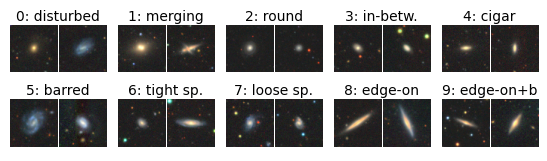

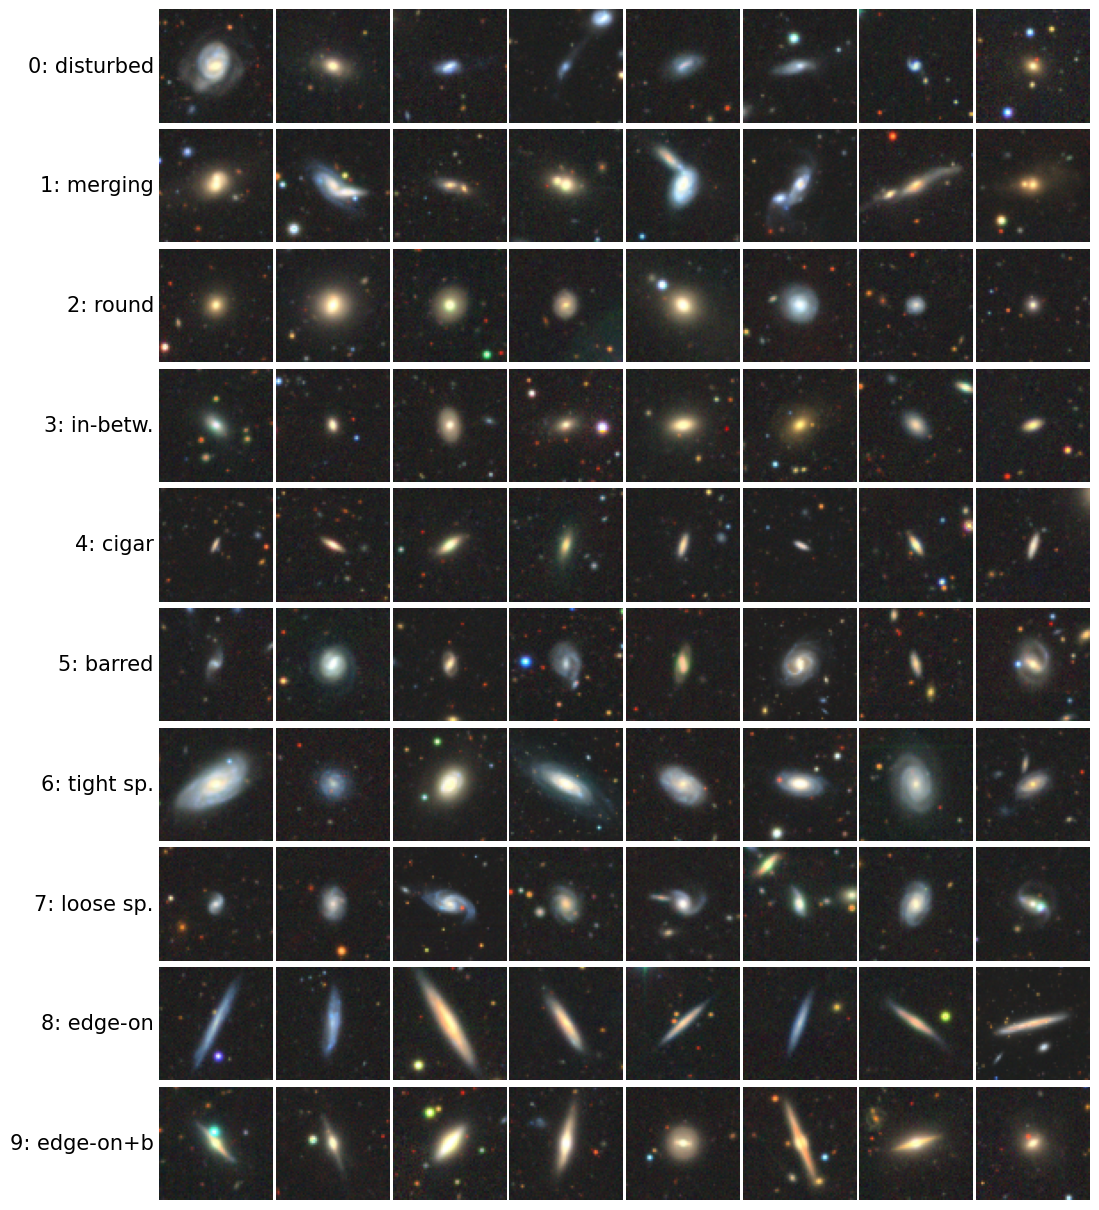

In [3]:
def image_axes(a):
    """Remove ticks and frame of an image panel."""
    a.set_xticks([]); a.set_yticks([])
    for sp in a.spines.values():
        sp.set_visible(False)


rng = np.random.default_rng(0)
with mpl.rc_context(SLIDE_RC):
    # two bands of five classes; each class shows two random galaxies side by side
    fig, axs = plt.subplots(2, 14, figsize=(SLIDE_W, 1.7),
                            gridspec_kw=dict(width_ratios=[1, 1, 0.18] * 4 + [1, 1], wspace=0.04, hspace=0.32))
    fig.subplots_adjust(left=0.02, right=0.98)            # full width, so the class labels do not touch
    for a in axs[:, 2::3].ravel():
        a.axis("off")                                     # narrow spacer columns between classes
    for k in range(10):
        pick = rng.choice(np.flatnonzero(labels == k), 2, replace=False)
        band, col = divmod(k, 5)
        for j, i in enumerate(pick):
            a = axs[band, 3 * col + j]
            a.imshow(images[i]); image_axes(a)
        a.set_title(f"{k}: {SHORT[k]}", fontsize=10, x=-0.02, pad=3)   # centred over the pair
    save(fig, "gen_gal_classes.png")
    plt.show()

fig, axs = plt.subplots(10, 8, figsize=(12, 15.5))
for k in range(10):
    for j, i in enumerate(rng.choice(np.flatnonzero(labels == k), 8, replace=False)):
        axs[k, j].imshow(images[i]); image_axes(axs[k, j])
    axs[k, 0].set_ylabel(f"{k}: {SHORT[k]}", rotation=0, ha="right", va="center")
plt.subplots_adjust(wspace=0.03, hspace=0.03)
plt.show()

The next cell splits one barred spiral into its three channels and shows the distribution of pixel values. Most pixels belong to the sky, which sits near the same value in every channel; the galaxy occupies the long tail to the right. This shape of the histogram will decide the form of the decoder likelihood in Section 2.

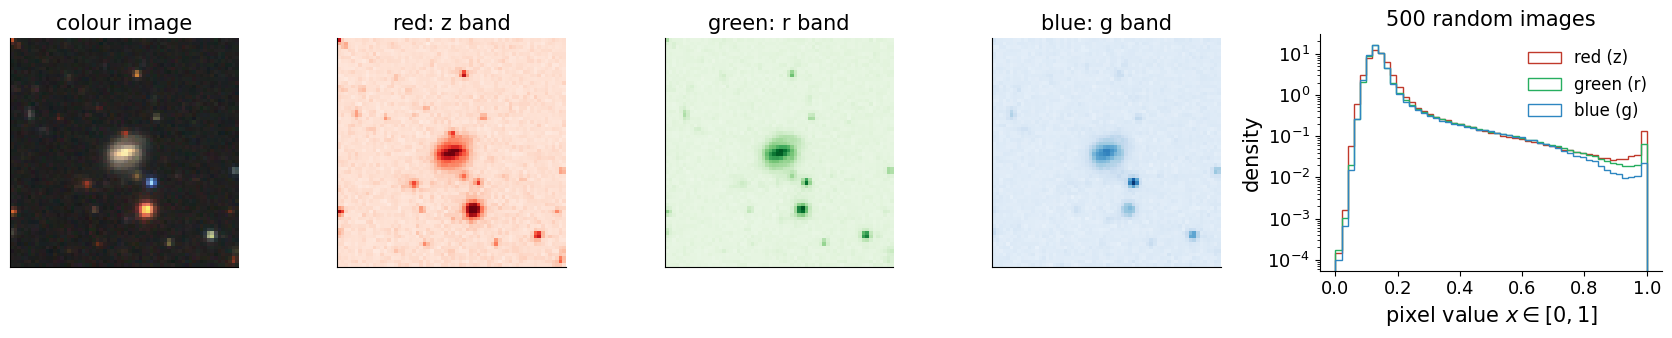

class of the example: Barred spiral; median pixel value of the 4x4 corners (empty sky) over all images: 0.125


In [4]:
i_ex = np.flatnonzero(labels == 5)[3]
img = images[i_ex].astype(np.float32) / 255
fig, axs = plt.subplots(1, 5, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1.5]))
axs[0].imshow(images[i_ex]); axs[0].set_title("colour image")
for c, (name, cm) in enumerate([("red: z band", "Reds"), ("green: r band", "Greens"),
                                ("blue: g band", "Blues")]):
    axs[c + 1].imshow(img[..., c], cmap=cm, vmin=0, vmax=1); axs[c + 1].set_title(name)
for a in axs[:4]:
    a.set_xticks([]); a.set_yticks([])
sample = images[rng.choice(N_IMG, 500, replace=False)].reshape(-1, 3) / 255
for c, col in enumerate(["#c0392b", "#27ae60", "#2e86c1"]):
    axs[4].hist(sample[:, c], bins=np.linspace(0, 1, 52), histtype="step", color=col, density=True,
                label=["red (z)", "green (r)", "blue (g)"][c])
axs[4].set_yscale("log"); axs[4].set_xlabel("pixel value $x \\in [0,1]$"); axs[4].set_ylabel("density")
axs[4].legend(); axs[4].set_title("500 random images")
plt.tight_layout(); plt.show()
border = images[:, :4, :4].reshape(-1, 3) / 255
nums["sky_level_median"] = float(np.median(border))
print(f"class of the example: {CLASS_NAMES[labels[i_ex]]}; median pixel value of the 4x4 corners "
      f"(empty sky) over all images: {nums['sky_level_median']:.3f}")

The images in the file are ordered by class, so a random permutation with a fixed seed decides the split: 2,736 images for testing and 15,000 for training. The β-VAE and the classifier use the same split, so that every statistic below is computed on galaxies that neither network has seen.

In [5]:
N_TEST = 2736
perm = np.random.default_rng(2027).permutation(N_IMG)
idx_te, idx_tr = perm[:N_TEST], perm[N_TEST:]

def to_tensor(a):
    """uint8 (n, 64, 64, 3) -> float32 tensor (n, 3, 64, 64) in [0, 1], channels-last memory layout."""
    t = torch.from_numpy(a).permute(0, 3, 1, 2).float().div_(255.0)
    return t.contiguous(memory_format=torch.channels_last)

Xtr, Xte = to_tensor(images[idx_tr]), to_tensor(images[idx_te])
ytr, yte = torch.from_numpy(labels[idx_tr]), torch.from_numpy(labels[idx_te])
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))
print("test-set class fractions:", np.round(np.bincount(yte.numpy(), minlength=10) / N_TEST, 3))

train (15000, 3, 64, 64) test (2736, 3, 64, 64)
test-set class fractions: [0.06  0.098 0.157 0.117 0.02  0.115 0.103 0.154 0.072 0.105]


<hr/>
## 2. The β-VAE loss

A variational autoencoder (Lab 024) describes an image $\mathbf x\in\mathbb R^D$, here $D=3\cdot64\cdot64=12\,288$, through a latent vector $\mathbf z\in\mathbb R^d$ with prior $p(\mathbf z)=\mathcal N(0,I_d)$ and a decoder distribution $p_\theta(\mathbf x|\mathbf z)$ with parameters $\theta$. The log-likelihood $\log p_\theta(\mathbf x)=\log\int p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)\,d\mathbf z$ is an integral that cannot be computed. An encoder $q_\phi(\mathbf z|\mathbf x)=\mathcal N\big(\boldsymbol\mu_\phi(\mathbf x),\operatorname{diag}\boldsymbol\sigma^2_\phi(\mathbf x)\big)$ with parameters $\phi$ proposes the latent vectors that could have produced $\mathbf x$. Multiplying and dividing by $q_\phi$ under the integral and applying Jensen's inequality $\log\mathbb E[\cdot]\ge\mathbb E[\log\,\cdot\,]$ gives

$$
\begin{aligned}
\log p_\theta(\mathbf x)&=\log\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\!\left[\frac{p_\theta(\mathbf x|\mathbf z)\,p(\mathbf z)}{q_\phi(\mathbf z|\mathbf x)}\right]\\
&\ge\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[\log p_\theta(\mathbf x|\mathbf z)\big]-\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p(\mathbf z)\big)\\
&\equiv\mathrm{ELBO}(\mathbf x).
\end{aligned}
$$

The ELBO, the evidence lower bound, is a computable lower bound on the log-likelihood $\log p_\theta(\mathbf x)$ (the "evidence"); $\mathrm{KL}(q\|p)=\mathbb E_q[\log q-\log p]\ge0$ is the Kullback–Leibler divergence, and the gap of the bound equals $\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,p_\theta(\mathbf z|\mathbf x)\big)$. The VAE minimises $-\mathrm{ELBO}$. The β-VAE [Higgins *et al.*, ICLR 2017, [openreview.net/forum?id=Sy2fzU9gl](https://openreview.net/forum?id=Sy2fzU9gl)] multiplies the KL term by a weight $\beta$:

$$
\begin{aligned}
\mathcal L_\beta(\mathbf x)&=\mathbb E_{q_\phi(\mathbf z|\mathbf x)}\big[-\log p_\theta(\mathbf x|\mathbf z)\big]\\
&\quad+\beta\,\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,\mathcal N(0,I_d)\big).
\end{aligned}
$$

For $\beta=1$ this is the VAE loss $-\mathrm{ELBO}$. For $\beta>1$, since the KL term is non-negative, $-\mathcal L_\beta\le\mathrm{ELBO}$ is still a lower bound on $\log p_\theta(\mathbf x)$, only a looser one. The expectation over $q_\phi$ is estimated, as in Lab 024, with one sample $\mathbf z=\boldsymbol\mu_\phi(\mathbf x)+\boldsymbol\sigma_\phi(\mathbf x)\odot\boldsymbol\varepsilon$, $\boldsymbol\varepsilon\sim\mathcal N(0,I_d)$ (reparametrisation trick).

For a diagonal Gaussian encoder and the standard normal prior the KL term splits into a sum over latent coordinates,

$$
\begin{aligned}
\mathrm{KL}\big(q_\phi(\mathbf z|\mathbf x)\,\|\,\mathcal N(0,I_d)\big)&=\sum_{k=1}^{d}\mathrm{KL}_k(\mathbf x),\\
\mathrm{KL}_k(\mathbf x)&=\tfrac12\big(\mu_k^2+\sigma_k^2-\ln\sigma_k^2-1\big)\ge0,
\end{aligned}
$$

with $\mu_k=\mu_{\phi,k}(\mathbf x)$ and $\sigma_k=\sigma_{\phi,k}(\mathbf x)$. A term vanishes only when $\mu_k=0$ and $\sigma_k=1$, that is when coordinate $k$ looks the same for every image and carries no information about $\mathbf x$. Averaged over the data, the KL term is an upper bound on the mutual information between image and code, measured in nats (1 nat $=1/\ln2$ bits). The β-VAE loss therefore charges a price $\beta$ for each nat of information that the code carries about the image, and the price is paid coordinate by coordinate.

Three properties of this price favour disentangled codes when $\beta>1$ [Burgess *et al.*, [arXiv:1804.03599](https://arxiv.org/abs/1804.03599)]. Information is expensive, so the encoder buys only a few nats and spends them where they reduce the reconstruction error most, which means on the factors of variation that change many pixels: for galaxies we expect size, elongation, orientation, brightness and colour long before spiral arms. The prior $\mathcal N(0,I_d)=\prod_k\mathcal N(0,1)$ is factorised, and the data-averaged KL contains the total correlation of the codes, a measure of the statistical dependence between coordinates (the rate decomposition of Lab 026 [Chen *et al.*, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942)]); a larger $\beta$ pushes the coordinates towards independence, so independent factors tend to end up in different coordinates. Finally, the posterior is diagonal: a rotated code, in which every coordinate mixes two factors, would need correlated posteriors, which the diagonal family cannot represent, and this breaks the rotation symmetry of the prior in favour of particular axes [Rolinek *et al.*, [arXiv:1812.06775](https://arxiv.org/abs/1812.06775)]. The price of all three effects is the same: fewer nats in the code mean less detail in the reconstruction. Lab 026 measured this trade-off along the rate–distortion curve; here we look at it on galaxies.

The remaining choice is the decoder distribution. Lab 024 treated every pixel of an MNIST digit as an independent coin with probability $\hat x_i$ of being black, a Bernoulli distribution, for which $-\log p_\theta(\mathbf x|\mathbf z)$ is the binary cross-entropy (BCE)
$$
\mathrm{BCE}(\mathbf x,\hat{\mathbf x})=-\sum_{i=1}^{D}\big[x_i\ln\hat x_i+(1-x_i)\ln(1-\hat x_i)\big],
$$
with $x_i$ the value of pixel $i$ and $\hat x_i$ its decoded value. The BCE is the natural measure of mismatch when pixels are close to 0 or 1, as for digits. Galaxy pixels are continuous, and most of them belong to the sky at values near 0.13, where the BCE is a shallow function of $\hat x_i$: a small error in a faint galaxy costs almost nothing, and the encoder finds it cheaper to store no information at all (Exercise 1). We therefore use a Gaussian decoder with a fixed width $\sigma_x$, which penalises the squared difference between the image and its reconstruction,

$$
-\log p_\theta(\mathbf x|\mathbf z)=\frac{\|\mathbf x-\hat{\mathbf x}_\theta(\mathbf z)\|^2}{2\sigma_x^2}+\frac D2\ln\big(2\pi\sigma_x^2\big),
$$

where $\hat{\mathbf x}_\theta(\mathbf z)\in(0,1)^D$ is the mean image produced by the decoder network, $\|\mathbf v\|^2=\sum_i v_i^2$, and $\sigma_x$ is the typical size of the pixel deviations that the model treats as noise; the constant is dropped in the code. To compare models we also report the mean squared error (MSE) per pixel of the reconstruction from the posterior mean, $\mathrm{MSE}=\frac1{ND}\sum_{n=1}^{N}\|\mathbf x_n-\hat{\mathbf x}_\theta(\boldsymbol\mu_\phi(\mathbf x_n))\|^2$ over $N$ test images: $\sqrt{\mathrm{MSE}}$ is the typical error of one pixel value. The width $\sigma_x$ sets the exchange rate between the two terms: one nat in the code pays off when it lowers the summed squared error $\|\mathbf x-\hat{\mathbf x}\|^2$ by $2\beta\sigma_x^2$. We use $\sigma_x=$0.15.

<hr/>
## 3. A convolutional β-VAE

The encoder applies four convolutions with $4\times4$ kernels and stride 2, each followed by a rectified linear unit (ReLU), the elementwise function $\mathrm{ReLU}(u)=\max(0,u)$, so that the image shrinks $64\to32\to16\to8\to4$ pixels while the number of channels grows to 16, 32, 32 and 64. A dense layer of 256 units then produces $2d=20$ numbers, the means $\boldsymbol\mu$ and the log-variances $\log\boldsymbol\sigma^2$ of a latent code of dimension $d=10$. The decoder mirrors the encoder with transposed convolutions, which double the image size at each step, and a final logistic sigmoid $1/(1+e^{-u})$, which maps every output to the interval $(0,1)$ of pixel values, gives the mean image $\hat{\mathbf x}_\theta(\mathbf z)$. The layer-by-layer table below comes from `torchinfo.summary`, which runs one forward pass and records the shape of every intermediate tensor and the number of trainable parameters of every layer.

In [6]:
D_LATENT = 10
SIGMA_X = 0.15      # standard deviation of the Gaussian decoder p(x|z), in pixel-value units


class BetaVAE(nn.Module):
    """Convolutional VAE for 3 x 64 x 64 images with a d-dimensional diagonal-Gaussian latent code."""

    def __init__(self, d=D_LATENT, ch=(16, 32, 32, 64), hidden=256):
        super().__init__()
        c = [3, *ch]
        enc = []
        for a, b in zip(c[:-1], c[1:]):          # each 4x4 convolution with stride 2 halves the image
            enc += [nn.Conv2d(a, b, 4, stride=2, padding=1), nn.ReLU()]
        self.encoder = nn.Sequential(*enc, nn.Flatten(),
                                     nn.Linear(ch[-1] * 4 * 4, hidden), nn.ReLU(),
                                     nn.Linear(hidden, 2 * d))          # mu and log sigma^2
        dec = [nn.Linear(d, hidden), nn.ReLU(), nn.Linear(hidden, ch[-1] * 4 * 4), nn.ReLU(),
               nn.Unflatten(1, (ch[-1], 4, 4))]
        r = [*ch[::-1], 3]
        for i, (a, b) in enumerate(zip(r[:-1], r[1:])):   # each transposed convolution doubles the image
            dec += [nn.ConvTranspose2d(a, b, 4, stride=2, padding=1)]
            if i < len(r) - 2:
                dec += [nn.ReLU()]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=1)
        return mu, logvar

    def decode(self, z):
        return torch.sigmoid(self.decoder(z))           # mean image x_hat(z), pixel values in (0, 1)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)   # reparametrisation trick
        return self.decode(z), mu, logvar


def beta_vae_loss(x, x_hat, mu, logvar, beta, sigma_x=SIGMA_X):
    """Minibatch average of L_beta; also returns the reconstruction term and the KL of each coordinate."""
    rec = ((x - x_hat) ** 2).sum(dim=(1, 2, 3)) / (2 * sigma_x ** 2)   # -log p(x|z) up to a constant
    kl_k = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1)                # KL per latent coordinate
    return (rec + beta * kl_k.sum(1)).mean(), rec.mean(), kl_k.mean(0)


print(summary(BetaVAE(), input_size=(1, 3, 64, 64), depth=2,
              col_names=("input_size", "output_size", "num_params"), verbose=0))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
BetaVAE                                  [1, 3, 64, 64]            [1, 3, 64, 64]            --
├─Sequential: 1-1                        [1, 3, 64, 64]            [1, 20]                   --
│    └─Conv2d: 2-1                       [1, 3, 64, 64]            [1, 16, 32, 32]           784
│    └─ReLU: 2-2                         [1, 16, 32, 32]           [1, 16, 32, 32]           --
│    └─Conv2d: 2-3                       [1, 16, 32, 32]           [1, 32, 16, 16]           8,224
│    └─ReLU: 2-4                         [1, 32, 16, 16]           [1, 32, 16, 16]           --
│    └─Conv2d: 2-5                       [1, 32, 16, 16]           [1, 32, 8, 8]             16,416
│    └─ReLU: 2-6                         [1, 32, 8, 8]             [1, 32, 8, 8]             --
│    └─Conv2d: 2-7                       [1, 32, 8, 8]             [1, 64, 4, 4]             32,832
│    └─ReLU: 2-8       

A table is precise but hides the structure. The function `draw_network` below draws the same network as columns of nodes joined by edges. In a convolutional column a node stands for a whole channel (a feature map), not for a pixel, and edges join only nearby nodes as a reminder that a convolution looks at a small patch of its input; dense columns are connected all-to-all. Columns with more units than `max_nodes` are cut, which the vertical ellipsis marks. The orange column is the latent code $\mathbf z$, the only place where randomness enters.

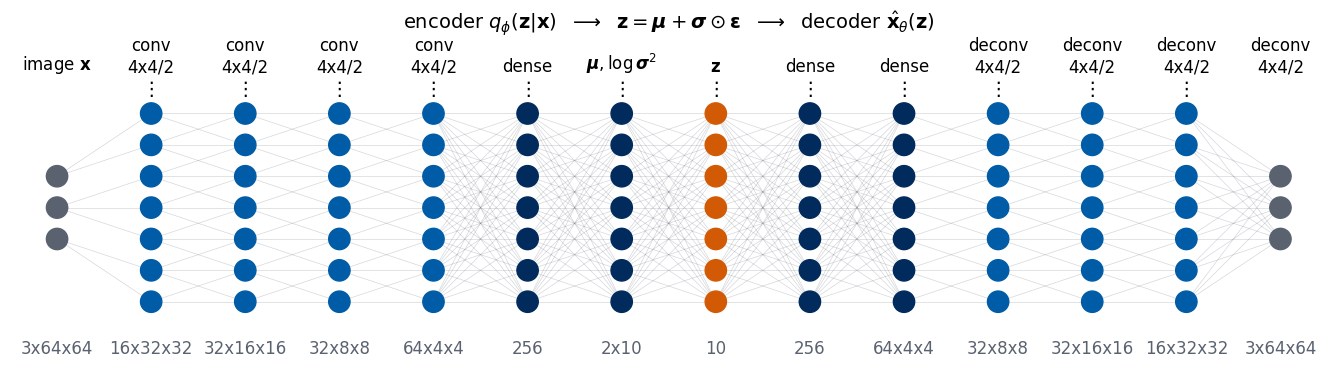

In [7]:
def draw_network(layers, ax=None, max_nodes=8, node_radius=0.17, x_gap=1.5, edge_alpha=0.25,
                 colors=None, title=None, fontsize=12):
    """Draw a feed-forward network as columns of nodes joined by edges.

    Parameters
    ----------
    layers : list of dict
        One dict per layer, in the order in which the data flow through the network. Keys:
          'name'  : str, label printed above the column (e.g. 'conv 4x4/2');
          'shape' : str, shape of the tensor the layer outputs, printed below the column
                    (e.g. '16x32x32' = channels x height x width);
          'n'     : int, number of units of the layer: channels for a convolution, neurons for
                    a dense layer; only min(n, max_nodes) nodes are drawn, and a vertical
                    ellipsis marks the ones left out;
          'kind'  : str, one of 'input', 'conv', 'dense', 'latent', 'output'; it sets the colour
                    of the nodes and the edges to the previous column: a 'conv' column is joined
                    only to the nearest nodes of the previous one (a picture of a local receptive
                    field), every other column to all nodes of the previous one.
    ax : matplotlib.axes.Axes or None
        Axes to draw into; when None a new figure of a suitable width is created.
    max_nodes : int
        Largest number of nodes drawn in one column.
    node_radius : float
        Radius of a node in data units; nodes in a column are 0.5 apart.
    x_gap : float
        Horizontal distance between consecutive columns, in data units.
    edge_alpha : float
        Opacity of the edges, between 0 and 1; small values keep fully connected layers readable.
    colors : dict or None
        Map from 'kind' to a matplotlib colour; kinds that are missing use the default colours.
    title : str or None
        Title written above the drawing.
    fontsize : float
        Font size of the layer names and shapes.

    Returns
    -------
    matplotlib.axes.Axes
        The axes with the drawing.
    """
    default = {"input": UJGray, "conv": UJBlue, "dense": UJNavy, "latent": DSOrange, "output": UJGray}
    colors = {**default, **(colors or {})}
    if ax is None:
        _, ax = plt.subplots(figsize=(1.0 * x_gap * len(layers) + 1, 3.6))
    columns = []                                         # (x, y) positions of the drawn nodes
    for i, layer in enumerate(layers):
        m = min(layer["n"], max_nodes)
        ys = 0.5 * (np.arange(m) - (m - 1) / 2)          # centred column
        columns.append([(i * x_gap, y) for y in ys])
    for i in range(1, len(layers)):                      # edges first, so that nodes cover them
        prev, cur = columns[i - 1], columns[i]
        for j, (x1, y1) in enumerate(cur):
            for (x0, y0) in prev:
                if layers[i]["kind"] == "conv":
                    # local connectivity: join nodes at similar relative height only
                    rel0 = y0 / (abs(prev[0][1]) + 1e-9)
                    rel1 = y1 / (abs(cur[0][1]) + 1e-9)
                    if abs(rel0 - rel1) > 0.45:
                        continue
                ax.plot([x0, x1], [y0, y1], color=UJGray, lw=0.5, alpha=edge_alpha, zorder=1)
    top = max(abs(c[0][1]) for c in columns) + 0.6
    for i, layer in enumerate(layers):
        for (x, y) in columns[i]:
            ax.add_patch(plt.Circle((x, y), node_radius, color=colors[layer["kind"]], zorder=2))
        x = i * x_gap
        if layer["n"] > max_nodes:
            ax.text(x, columns[i][-1][1] + 0.38, "\u22ee", ha="center", va="center", fontsize=fontsize + 2)
        ax.text(x, top, layer["name"], ha="center", va="bottom", fontsize=fontsize, rotation=0)
        ax.text(x, -top, layer["shape"], ha="center", va="top", fontsize=fontsize, color=UJGray)
    ax.set_xlim(-x_gap / 2, (len(layers) - 0.5) * x_gap)
    ax.set_ylim(-top - 0.6, top + 0.6)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=fontsize + 2)
    return ax


vae_layers = [
    dict(name="image $\\mathbf{x}$", shape="3x64x64", n=3, kind="input"),
    dict(name="conv\n4x4/2", shape="16x32x32", n=16, kind="conv"),
    dict(name="conv\n4x4/2", shape="32x16x16", n=32, kind="conv"),
    dict(name="conv\n4x4/2", shape="32x8x8", n=32, kind="conv"),
    dict(name="conv\n4x4/2", shape="64x4x4", n=64, kind="conv"),
    dict(name="dense", shape="256", n=256, kind="dense"),
    dict(name="$\\boldsymbol{\\mu}, \\log\\boldsymbol{\\sigma}^2$", shape="2x10", n=20, kind="dense"),
    dict(name="$\\mathbf{z}$", shape="10", n=10, kind="latent"),
    dict(name="dense", shape="256", n=256, kind="dense"),
    dict(name="dense", shape="64x4x4", n=1024, kind="dense"),
    dict(name="deconv\n4x4/2", shape="32x8x8", n=32, kind="conv"),
    dict(name="deconv\n4x4/2", shape="32x16x16", n=32, kind="conv"),
    dict(name="deconv\n4x4/2", shape="16x32x32", n=16, kind="conv"),
    dict(name="deconv\n4x4/2", shape="3x64x64", n=3, kind="output"),
]
fig, ax = plt.subplots(figsize=(17, 5.0))
draw_network(vae_layers, ax=ax, max_nodes=7, title="encoder $q_\\phi(\\mathbf{z}|\\mathbf{x})$"
             "  $\\longrightarrow$  $\\mathbf{z} = \\boldsymbol{\\mu} + \\boldsymbol{\\sigma}\\odot\\boldsymbol{\\varepsilon}$"
             "  $\\longrightarrow$  decoder $\\hat{\\mathbf{x}}_\\theta(\\mathbf{z})$")
plt.show()

The same network can be drawn automatically. `torchview.draw_graph` traces one forward pass and draws the computation graph with the graphviz program `dot`: every box is a module or a tensor operation, labelled with the shapes of its inputs and outputs. Such a drawing is a quick check that the code builds the network we meant, for example that the encoder output is split into $\boldsymbol\mu$ and $\log\boldsymbol\sigma^2$ and that the reparametrisation (`exp`, `randn_like`, multiplication, addition) sits between encoder and decoder.

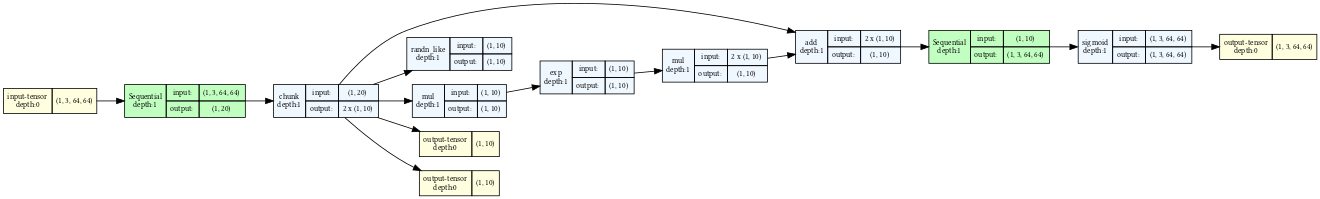

In [8]:
try:
    from torchview import draw_graph
    graph = draw_graph(BetaVAE(), input_size=(1, 3, 64, 64), depth=1, expand_nested=False,
                       graph_dir="LR", roll=False)
    graph.visual_graph.attr(dpi="110")
    png = graph.visual_graph.render(filename=f"{CKPT}/lab027_bvae_graph", format="png", cleanup=True)
    display(Image(png))
except Exception as err:          # torchview or the graphviz binary may be missing
    print("torchview / graphviz not available:", err)

Both models are trained with Adam (adaptive moment estimation, the gradient method of Lab 024 that rescales each parameter's step by running averages of its gradient and squared gradient) at learning rate $10^{-3}$ on minibatches of 128 images for 10 epochs over the 15,000 training images. The seed fixes the initial weights, the noise $\boldsymbol\varepsilon$ and the order of the minibatches, so a second run gives the same model. The weights and the training history are saved in `checkpoints/`; when a file exists, the notebook loads it instead of training again.

In [9]:
EPOCHS_VAE, BATCH, LR = 10, 128, 1e-3


def train_vae(beta, seed, epochs=EPOCHS_VAE, data=Xtr):
    """Train a beta-VAE with Adam, or load its weights from CKPT if they exist; returns (model, history)."""
    path = f"{CKPT}/lab027_bvae_beta{beta:g}_seed{seed}.pt"
    torch.manual_seed(seed)                                   # fixes the initial weights and the noise
    model = BetaVAE().to(memory_format=torch.channels_last)
    if os.path.exists(path):
        ck = torch.load(path, weights_only=False)
        model.load_state_dict(ck["state"])
        print(f"beta={beta:g}, seed={seed}: weights loaded from {path} "
              f"(trained {ck['train_time_s'] / 60:.1f} min)")
        return model.eval(), ck["history"]
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)                 # fixes the order of the minibatches
    n = data.shape[0]
    hist = {"rec": [], "kl": [], "kl_k": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        order = torch.randperm(n, generator=gen)
        rec_sum, kl_sum, klk_sum, nb = 0.0, 0.0, torch.zeros(D_LATENT), 0
        for i in range(0, n - BATCH + 1, BATCH):
            x = data[order[i:i + BATCH]]
            x_hat, mu, logvar = model(x)
            loss, rec, kl_k = beta_vae_loss(x, x_hat, mu, logvar, beta)
            opt.zero_grad(); loss.backward(); opt.step()
            rec_sum += rec.item(); kl_sum += kl_k.sum().item(); klk_sum += kl_k.detach(); nb += 1
        hist["rec"].append(rec_sum / nb); hist["kl"].append(kl_sum / nb); hist["kl_k"].append((klk_sum / nb).tolist())
        print(f"  beta={beta:g} seed={seed} epoch {ep + 1:2d}: reconstruction {hist['rec'][-1]:8.1f}"
              f"  KL {hist['kl'][-1]:6.2f} nats   ({time.time() - t0:5.0f} s)")
    torch.save({"state": model.state_dict(), "history": hist, "beta": beta, "seed": seed,
                "train_time_s": time.time() - t0}, path)
    return model.eval(), hist


models, hists = {}, {}
for beta in (1, 4):
    models[beta], hists[beta] = train_vae(beta, seed=0)

beta=1, seed=0: weights loaded from checkpoints/lab027_bvae_beta1_seed0.pt (trained 4.7 min)
beta=4, seed=0: weights loaded from checkpoints/lab027_bvae_beta4_seed0.pt (trained 7.4 min)


The left panel shows the reconstruction term $\|\mathbf x-\hat{\mathbf x}\|^2/(2\sigma_x^2)$ and the right panel the KL term, both averaged over the training minibatches of each epoch. After the first epoch the reconstruction term (6,522 nats for both models) falls steeply while the KL term grows: the encoder starts to buy information as soon as it pays off. After ten epochs the $\beta=1$ model stores 25.2 nats per image and the $\beta=4$ model 11.4 nats, less than half, while its reconstruction term is only slightly higher (863 against 846 nats). On the test images the KL is 25.31 and 11.38 nats, and the mean squared error per pixel of the reconstruction from the posterior mean is 0.00301 for $\beta=1$ and 0.00313 for $\beta=4$, a typical pixel error of $\sqrt{0.003}\approx0.055$. Most of the extra price of $\beta=4$ is paid by giving up information, not by worse reconstructions; the curves are still slowly falling, so longer training would improve both models.

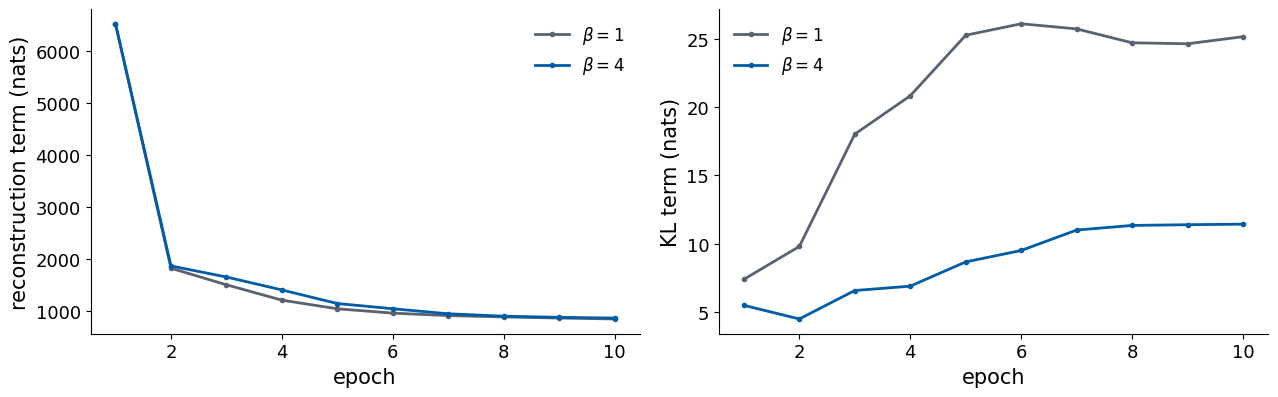

beta=1: test mean squared error per pixel of x_hat(mu) = 0.00301, KL = 25.31 nats per image


beta=4: test mean squared error per pixel of x_hat(mu) = 0.00313, KL = 11.38 nats per image


In [10]:
@torch.no_grad()
def encode_all(model, X, chunk=1000):
    """Posterior means and log-variances of all images in X."""
    mus, lvs = [], []
    for i in range(0, X.shape[0], chunk):
        mu, lv = model.encode(X[i:i + chunk]); mus.append(mu); lvs.append(lv)
    return torch.cat(mus).numpy(), torch.cat(lvs).numpy()


@torch.no_grad()
def decode_all(model, Z, chunk=1000):
    """Decoded mean images x_hat(z), as a float tensor (n, 3, 64, 64)."""
    Z = torch.as_tensor(Z, dtype=torch.float32)
    return torch.cat([model.decode(Z[i:i + chunk]) for i in range(0, Z.shape[0], chunk)])


enc = {b: encode_all(models[b], Xte) for b in models}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for b, col in [(1, UJGray), (4, UJBlue)]:
    ep = np.arange(1, len(hists[b]["rec"]) + 1)
    axs[0].plot(ep, hists[b]["rec"], "o-", color=col, ms=3, label=f"$\\beta={b}$")
    axs[1].plot(ep, hists[b]["kl"], "o-", color=col, ms=3, label=f"$\\beta={b}$")
axs[0].set_ylabel("reconstruction term (nats)"); axs[1].set_ylabel("KL term (nats)")
for a in axs:
    a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

nums["test_mse"], nums["test_kl"] = {}, {}
for b in models:
    mu, lv = enc[b]
    x_hat = decode_all(models[b], mu)
    nums["test_mse"][b] = float(((x_hat - Xte) ** 2).mean())
    nums["test_kl"][b] = float((0.5 * (mu ** 2 + np.exp(lv) - lv - 1)).sum(1).mean())
    print(f"beta={b}: test mean squared error per pixel of x_hat(mu) = {nums['test_mse'][b]:.5f}, "
          f"KL = {nums['test_kl'][b]:.2f} nats per image")

The figure shows one test galaxy of each class (top row) and its reconstructions $\hat{\mathbf x}_\theta(\boldsymbol\mu_\phi(\mathbf x))$ by the two models. What survives the bottleneck is the size, the brightness, the elongation and the orientation of the central light distribution. Spiral arms, bars, merging companions, neighbouring stars, and even the colour are lost: the reconstructions are almost grey. With 11 to 25 nats per image the models cannot afford them, and their contribution to the squared error over 12,288 pixel values is small. The difference between $\beta=1$ and $\beta=4$ is barely visible at this level; it lies in how the information is distributed over the coordinates, which the next section examines.

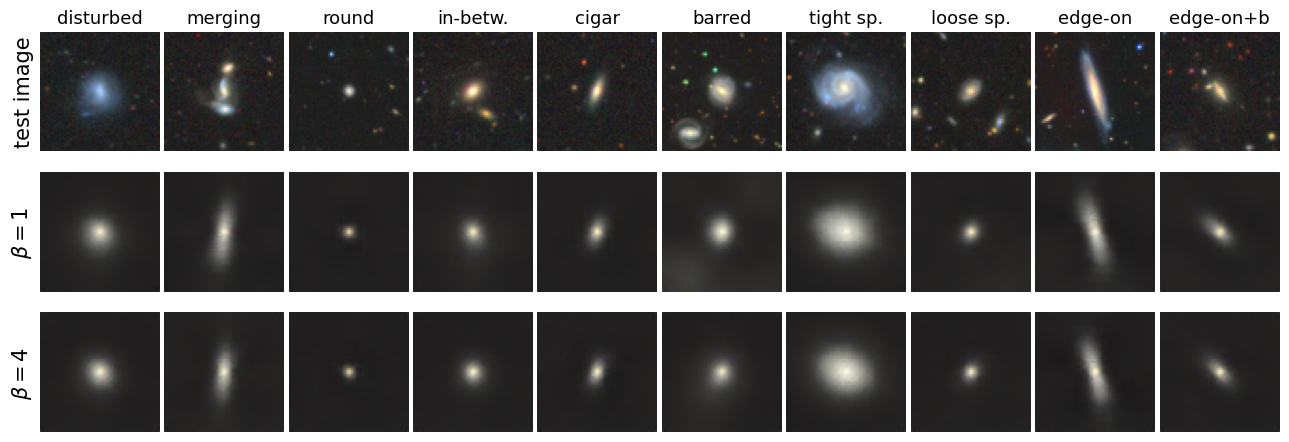

In [11]:
show = np.array([np.flatnonzero(yte.numpy() == k)[0] for k in range(10)])
rows = [("test image", Xte[show])] + [(f"$\\beta={b}$", decode_all(models[b], enc[b][0][show])) for b in (1, 4)]
fig, axs = plt.subplots(3, 10, figsize=(16, 5.4))
for r, (name, ims) in enumerate(rows):
    for c in range(10):
        axs[r, c].imshow(ims[c].permute(1, 2, 0).numpy()); image_axes(axs[r, c])
        if r == 0:
            axs[r, c].set_title(SHORT[yte[show[c]]], fontsize=13)
    axs[r, 0].set_ylabel(name)
plt.subplots_adjust(wspace=0.04, hspace=0.04)
plt.show()

<hr/>
## 4. Active coordinates and latent traversals

The KL term of the loss tells us which latent coordinates the model actually uses. For each coordinate $k$ we average its KL contribution over the test images,

$$
\overline{\mathrm{KL}}_k=\frac1N\sum_{n=1}^{N}\tfrac12\big(\mu_k(\mathbf x_n)^2+\sigma_k(\mathbf x_n)^2-\ln\sigma_k(\mathbf x_n)^2-1\big),
$$

and call the coordinate active when $\overline{\mathrm{KL}}_k>0.1$ nats, the threshold used in Labs 024 and 026. An inactive coordinate has $\mu_k\approx0$ and $\sigma_k\approx1$ for every image: the encoder writes nothing into it and the decoder has learned to ignore it, so moving along it changes nothing. The bar chart sorts the coordinates of each model by $\overline{\mathrm{KL}}_k$; the dashed line is the threshold.

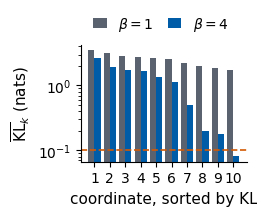

beta=1: KL per coordinate (sorted) [3.48 3.19 2.84 2.74 2.67 2.59 2.22 1.99 1.85 1.73]; active [3, 9, 0, 8, 2, 5, 7, 1, 4, 6]
beta=4: KL per coordinate (sorted) [2.63 1.91 1.73 1.68 1.35 1.11 0.51 0.2  0.18 0.08]; active [5, 2, 7, 9, 3, 1, 8, 4, 0]


In [12]:
KL_ACTIVE = 0.1          # nats; same threshold as in Labs 024 and 026
kl_dim, active = {}, {}
for b in models:
    mu, lv = enc[b]
    kl_dim[b] = (0.5 * (mu ** 2 + np.exp(lv) - lv - 1)).mean(0)
    active[b] = [int(k) for k in np.argsort(-kl_dim[b]) if kl_dim[b][k] > KL_ACTIVE]   # sorted by KL
nums["n_active"] = {b: len(active[b]) for b in models}
nums["kl_per_dim"] = {b: kl_dim[b].tolist() for b in models}

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(SLIDE_HALF, 2.3))
    rank = np.arange(1, D_LATENT + 1)
    for b, col, off in [(1, UJGray, -0.2), (4, UJBlue, 0.2)]:
        ax.bar(rank + off, np.sort(kl_dim[b])[::-1], 0.4, color=col, label=f"$\\beta={b}$")
    ax.axhline(KL_ACTIVE, color=DSOrange, lw=1.2, ls="--")
    ax.set_yscale("log"); ax.set_xticks(rank)
    ax.set_xlabel("coordinate, sorted by KL"); ax.set_ylabel("$\\overline{\\mathrm{KL}}_k$ (nats)")
    ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=2, handlelength=1.0, columnspacing=1.0)
    plt.tight_layout(); save(fig, "gen_gal_kl.png"); plt.show()
for b in models:
    print(f"beta={b}: KL per coordinate (sorted) {np.round(np.sort(kl_dim[b])[::-1], 2)}; active {active[b]}")

At $\beta=1$ all ten coordinates are active, with $\overline{\mathrm{KL}}_k$ between 1.73 and 3.48 nats. At $\beta=4$ nine are active, between 0.18 and 2.63 nats, and the tenth carries 0.08 nats: the higher price has not switched many coordinates off, but it has made a few of them nearly empty and spread the rest unevenly, with the largest coordinate carrying 2.63 nats. Which properties of the galaxy these coordinates carry is the next question.

A latent traversal starts from the code $\mathbf z_0=\boldsymbol\mu_\phi(\mathbf x_0)$ of one galaxy, changes one coordinate, $z_k=z_{0,k}+v$ with $v\in[-3,3]$ in units of the prior standard deviation, keeps all other coordinates fixed, and decodes. As base galaxy $\mathbf x_0$ we take the test galaxy whose $\beta=4$ code lies closest to the origin, a typical galaxy of the data set (it is a round smooth galaxy). The first figure, drawn for the slides, compares the four coordinates with the largest $\overline{\mathrm{KL}}_k$ of each model on seven values of $v$; the second shows all active coordinates of the $\beta=4$ model. In each row, look for whether one property of the image changes or several at once.

In the $\beta=4$ model the rows are easy to describe. Along $z_5$ the galaxy grows from a faint point into a large bright blob, so size and brightness change together. Along $z_2$ a round image is stretched along one diagonal for negative and along the other diagonal for positive values. Along $z_7$ and $z_9$ it is stretched along the horizontal or the vertical image axis, $z_7$ horizontal for negative values, $z_9$ vertical for negative values. The coordinates $z_3$ and $z_1$ add faint asymmetric light, and $z_8$, $z_4$ and $z_0$ produce no change visible by eye. In the $\beta=1$ model the leading rows mix properties: along $z_3$ the galaxy shrinks and turns at the same time, and $z_9$ changes brightness and compactness together with the shape. No row of either model changes the colour.

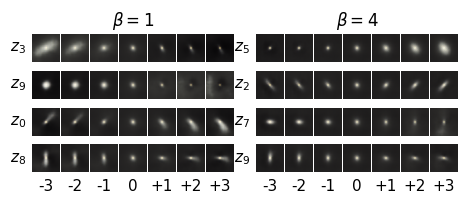

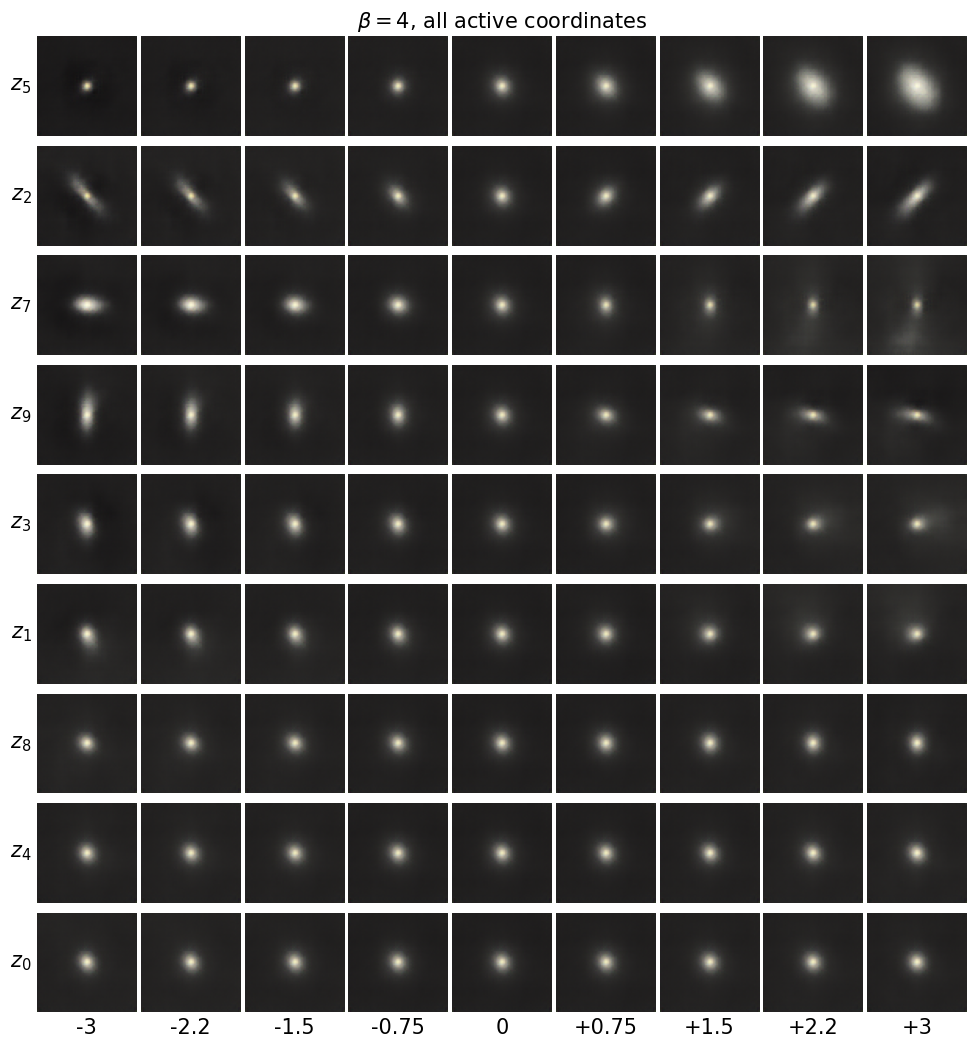

base galaxy: test image 1711 | class Round smooth


In [13]:
TRAV = np.linspace(-3, 3, 9)
mu4 = enc[4][0]
i_base = int(np.argmin((mu4 ** 2).sum(1)))      # the test galaxy whose code is closest to the origin (beta = 4)
nums["traversal_base_class"] = SHORT[int(yte[i_base])]


def traversal(model, z0, coords, values):
    """Decoded images with one coordinate k set to z0[k] + v, for each k in coords and v in values."""
    Z = np.repeat(z0[None], len(coords) * len(values), 0).reshape(len(coords), len(values), -1).copy()
    for r, k in enumerate(coords):
        Z[r, :, k] = z0[k] + values
    return decode_all(model, Z.reshape(-1, Z.shape[-1])).reshape(len(coords), len(values), 3, 64, 64)


def show_traversal(ims, coords, values, axs, title=None, xfmt="{:+.0f}"):
    """Grid of traversal images: row r = coordinate coords[r], column c = shift values[c]."""
    for r in range(ims.shape[0]):
        for c in range(ims.shape[1]):
            a = axs[r, c]
            a.imshow(ims[r, c].permute(1, 2, 0).numpy()); image_axes(a)
            if r == ims.shape[0] - 1:
                a.set_xlabel("0" if values[c] == 0 else xfmt.format(values[c]))
        axs[r, 0].set_ylabel(f"$z_{{{coords[r]}}}$", rotation=0, ha="right", va="center")
    if title:
        axs[0, ims.shape[1] // 2].set_title(title)


# slide figure: beta = 1 and beta = 4 side by side, five coordinates with the largest KL, shifts -3 ... 3
TRAV_S = np.linspace(-3, 3, 7)
n_rows = 4
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(SLIDE_W, 1.9))
    gs = fig.add_gridspec(n_rows, 2 * len(TRAV_S) + 1, wspace=0.04, hspace=0.04,
                          width_ratios=[1] * len(TRAV_S) + [0.7] + [1] * len(TRAV_S))
    for side, b in enumerate((1, 4)):
        coords = active[b][:n_rows]
        ims = traversal(models[b], enc[b][0][i_base], coords, TRAV_S)
        axs = np.array([[fig.add_subplot(gs[r, side * (len(TRAV_S) + 1) + c]) for c in range(len(TRAV_S))]
                        for r in range(len(coords))])
        show_traversal(ims, coords, TRAV_S, axs, f"$\\beta={b}$")
    save(fig, "gen_gal_traversal.png")
    plt.show()

# notebook figure: every active coordinate of the beta = 4 model, nine shifts
ims = traversal(models[4], enc[4][0][i_base], active[4], TRAV)
fig, axs = plt.subplots(len(active[4]), len(TRAV), figsize=(12, 1.35 * len(active[4]) + 0.6), squeeze=False)
show_traversal(ims, active[4], TRAV, axs, "$\\beta=4$, all active coordinates", xfmt="{:+.2g}")
plt.subplots_adjust(wspace=0.04, hspace=0.04)
plt.show()
print("base galaxy: test image", i_base, "| class", CLASS_NAMES[int(yte[i_base])])

<hr/>
## 5. Physical quantities measured from the images

Traversals are judged by eye, and the eye is easily convinced. To name a coordinate we need numbers that describe each galaxy and that do not come from the labels. The function below measures, from the pixels of each test image alone, the quantities that astronomers use to describe the light distribution of a galaxy.

The intensity of a pixel is the mean of its three channels, $I(x,y)$, with $x$ the column and $y$ the row index. The sky level $s$ is the median of $I$ over a frame of width 4 pixels along the image border, and the noise of the sky $\sigma_s$ is $1.4826$ times the median absolute deviation of the same pixels (for Gaussian noise this equals the standard deviation, while bright stars on the border do not inflate it). The galaxy mask is the connected region of pixels with $I-s>3\sigma_s$ that contains the image centre, after a morphological opening that removes isolated noisy pixels; foreground stars and neighbouring galaxies form separate regions and are left out. Inside the mask the pixel weights are $w=I-s$, the total weight is $F=\sum w$, and the flux-weighted centroid $(\bar x,\bar y)$ and second moments are

$$
I_{xx}=\frac1F\sum w\,(x-\bar x)^2,\qquad I_{yy}=\frac1F\sum w\,(y-\bar y)^2,\qquad I_{xy}=\frac1F\sum w\,(x-\bar x)(y-\bar y).
$$

From these we define seven quantities:

- size $R=\sqrt{A/\pi}$, the radius in pixels of a disc with the same area $A$ as the mask;
- axis ratio $q=\sqrt{\lambda_2/\lambda_1}$, where $\lambda_1\ge\lambda_2$ are the eigenvalues of the second-moment matrix; $q\approx1$ for a round image and $q\ll1$ for an elongated one. For a thin circular disk inclined by an angle $i$ to the line of sight $q\approx\cos i$, so for disk galaxies $q$ measures the inclination;
- ellipticity components $e_1=(I_{xx}-I_{yy})/(I_{xx}+I_{yy})$ and $e_2=2I_{xy}/(I_{xx}+I_{yy})$, which describe the orientation. The position angle $\theta=\tfrac12\operatorname{atan2}(2I_{xy},I_{xx}-I_{yy})$ is undefined for round galaxies and jumps by $\pi$; the components $e_1=\varepsilon\cos2\theta$ and $e_2=\varepsilon\sin2\theta$, with $\varepsilon=(\lambda_1-\lambda_2)/(\lambda_1+\lambda_2)=(1-q^2)/(1+q^2)$, are smooth functions of the image and are the same components used for galaxy shapes in weak gravitational lensing;
- brightness $F$, the summed sky-subtracted intensity in the mask, in the stretched units of the image (not a calibrated magnitude);
- colour $c=\frac1F\sum w\,(x_{\rm red}-x_{\rm blue})$, the flux-weighted difference between the red ($z$-band) and blue ($g$-band) channels; a larger $c$ means a redder galaxy. It plays the role of the astronomical colour index $g-z$, but in stretched units;
- concentration $C=r_{80}/r_{20}$, where $r_{80}$ and $r_{20}$ are the radii of circles around the centroid that contain 80% and 20% of $F$ ($r_{20}$ is kept above half a pixel). A galaxy dominated by a bright central bulge has a large $C$, a disk with a slowly falling profile a small one. At 64 pixels $r_{20}$ is often about one pixel, and a circular aperture on an edge-on disk also gives a large $C$, so this is the least reliable of the seven.

The classes are used only as a check: the cell prints the median of every quantity for each class.

In [14]:
def measure_galaxy(img, k_sigma=3.0):
    """Morphological quantities of the central galaxy of one image.

    img : float array (64, 64, 3), pixel values in [0, 1], channels (z, r, g) as (R, G, B).
    Returns a dict with the size R, axis ratio q, ellipticity components e1, e2, position angle pa,
    brightness F, colour c, concentration C and the boolean mask of the galaxy.
    """
    I = img.mean(-1)                                            # intensity: mean of the three bands
    edge = np.concatenate([I[:4].ravel(), I[-4:].ravel(), I[4:-4, :4].ravel(), I[4:-4, -4:].ravel()])
    sky = np.median(edge)
    noise = 1.4826 * np.median(np.abs(edge - sky)) + 1e-3       # robust standard deviation of the sky
    J = I - sky
    above = ndimage.binary_opening(J > k_sigma * noise)        # drop isolated noisy pixels
    lab, n = ndimage.label(above)
    H, W = I.shape
    yy, xx = np.mgrid[:H, :W]
    if n == 0:
        return None
    g = lab[H // 2, W // 2]
    if g == 0:                                                  # centre not above threshold: nearest region
        d2 = np.where(lab > 0, (yy - H / 2) ** 2 + (xx - W / 2) ** 2, np.inf)
        g = lab.ravel()[np.argmin(d2)]
    mask = lab == g
    w = np.where(mask, np.clip(J, 0, None), 0.0)
    Ftot = w.sum()
    yc, xc = (w * yy).sum() / Ftot, (w * xx).sum() / Ftot
    Ixx = (w * (xx - xc) ** 2).sum() / Ftot
    Iyy = (w * (yy - yc) ** 2).sum() / Ftot
    Ixy = (w * (xx - xc) * (yy - yc)).sum() / Ftot
    tr, det = Ixx + Iyy, Ixx * Iyy - Ixy ** 2
    disc = np.sqrt(max(tr ** 2 / 4 - det, 0.0))
    lam1, lam2 = tr / 2 + disc, max(tr / 2 - disc, 0.0)        # eigenvalues of the second-moment matrix
    r = np.hypot(yy - yc, xx - xc)[mask]
    f = w[mask]
    o = np.argsort(r)
    cum = np.cumsum(f[o]) / Ftot
    r20, r80 = np.interp(0.2, cum, r[o]), np.interp(0.8, cum, r[o])
    return dict(R=np.sqrt(mask.sum() / np.pi), q=np.sqrt(lam2 / lam1),
                e1=(Ixx - Iyy) / tr, e2=2 * Ixy / tr, pa=0.5 * np.arctan2(2 * Ixy, Ixx - Iyy),
                F=Ftot, c=(w * (img[..., 0] - img[..., 2])).sum() / Ftot, C=r80 / max(r20, 0.5),
                mask=mask, xc=xc, yc=yc, lam1=lam1, lam2=lam2)


QUANT = ["R", "q", "e1", "e2", "F", "c", "C"]
QLABEL = {"R": "size $R$", "q": "axis ratio $q$", "e1": "$e_1$", "e2": "$e_2$", "F": "brightness $F$",
          "c": "colour $c$", "C": "concentration $C$"}
t0 = time.time()
Xte_np = Xte.permute(0, 2, 3, 1).numpy()
meas = [measure_galaxy(im) for im in Xte_np]
ok = np.array([m is not None for m in meas])
Q = np.array([[m[k] for k in QUANT] if m is not None else [np.nan] * len(QUANT) for m in meas])
nums["n_measured"] = int(ok.sum())
print(f"measured {ok.sum()} of {len(meas)} test galaxies in {time.time() - t0:.1f} s")
print("medians per class:")
print("  " + " ".join(f"{k:>7s}" for k in QUANT))
for k in range(10):
    sel = ok & (yte.numpy() == k)
    print(f"  {' '.join(f'{v:7.3f}' for v in np.median(Q[sel], 0))}   {CLASS_NAMES[k]}")

measured 2735 of 2736 test galaxies in 4.1 s
medians per class:
        R       q      e1      e2       F       c       C
   10.660   0.609  -0.033   0.022  76.520  -0.019   2.891   Disturbed
   11.968   0.625  -0.009  -0.025 100.349   0.125   2.701   Merging
    9.950   0.888   0.002  -0.001  63.355   0.121   2.946   Round smooth
    8.463   0.650   0.051  -0.039  51.702   0.102   2.915   In-between round smooth
    8.029   0.437  -0.163   0.029  52.455   0.119   3.031   Cigar-shaped smooth
   12.760   0.770   0.003  -0.010 118.196   0.037   2.699   Barred spiral
   12.909   0.768   0.019   0.015 128.059   0.007   2.652   Unbarred tight spiral
   11.113   0.673  -0.068   0.016  90.400  -0.016   2.814   Unbarred loose spiral
   12.035   0.250  -0.025   0.161 112.970   0.034   3.598   Edge-on without bulge
    8.667   0.333   0.186  -0.068  54.098   0.183   3.499   Edge-on with bulge


The figure shows five test galaxies with the mask (orange contour) and the ellipse of the second moments (white, semi-axes $2\sqrt{\lambda_1}$ and $2\sqrt{\lambda_2}$). The mask should follow the galaxy and exclude its neighbours; the ellipse should follow its elongation and orientation.

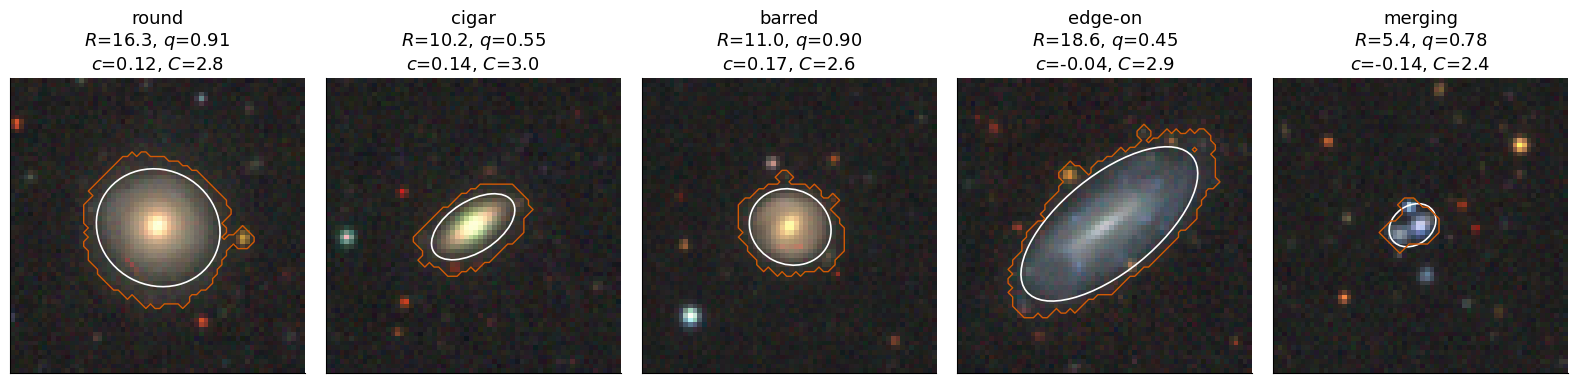

In [15]:
demo = [np.flatnonzero(ok & (yte.numpy() == k))[1] for k in (2, 4, 5, 8, 1)]
fig, axs = plt.subplots(1, len(demo), figsize=(16, 4.6))
for a, i in zip(axs, demo):
    m = meas[i]
    a.imshow(Xte_np[i])
    a.contour(m["mask"], levels=[0.5], colors=[DSOrange], linewidths=1)
    width, height = 4 * np.sqrt(m["lam1"]), 4 * np.sqrt(m["lam2"])    # 2-sigma ellipse of the moments
    a.add_patch(Ellipse((m["xc"], m["yc"]), width, height, angle=np.degrees(m["pa"]), fill=False,
                        color="white", lw=1.2))
    a.set_title(f"{SHORT[int(yte[i])]}\n$R$={m['R']:.1f}, $q$={m['q']:.2f}\n$c$={m['c']:.2f}, $C$={m['C']:.1f}",
                fontsize=13)
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

We compare each latent coordinate with each measured quantity through the Spearman rank correlation $\rho$, the Pearson correlation of the ranks of the two variables over the test galaxies. It equals $\pm1$ for any monotonic relation, so it does not depend on the nonlinear stretch of the pixel values or on how a coordinate is scaled. The latent value of an image is its posterior mean $\mu_k(\mathbf x)$. The matrix $|\rho(\mu_k,\text{quantity})|$ has one row per active coordinate, sorted by $\overline{\mathrm{KL}}_k$, and one column per quantity.

A coordinate is named after a quantity only when the correlation is clear: $|\rho|\ge0.5$, and larger by at least $0.15$ than the next-largest $|\rho|$ in the same row. The measured quantities are themselves correlated, for example a large galaxy is usually also a bright one, so a coordinate may correlate with two quantities at once; the margin rule then refuses to name it.

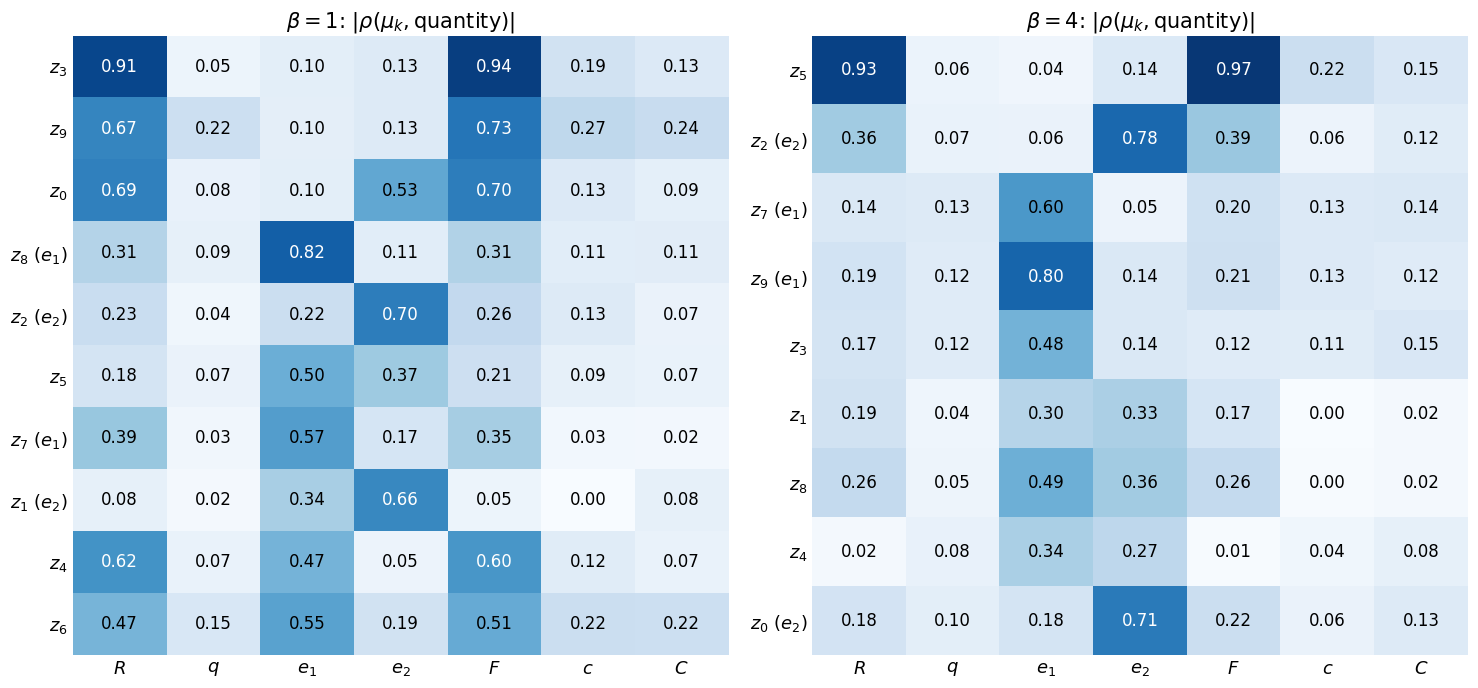

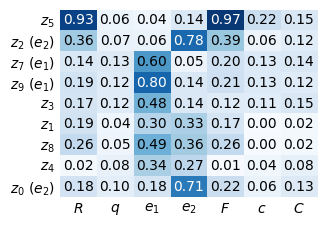

beta=1: named coordinates {8: 'e1', 2: 'e2', 7: 'e1', 1: 'e2'}
   largest |rho| per quantity: {'R': 0.91, 'q': 0.22, 'e1': 0.82, 'e2': 0.7, 'F': 0.94, 'c': 0.27, 'C': 0.24}
beta=4: named coordinates {2: 'e2', 7: 'e1', 9: 'e1', 0: 'e2'}
   largest |rho| per quantity: {'R': 0.93, 'q': 0.13, 'e1': 0.8, 'e2': 0.78, 'F': 0.97, 'c': 0.22, 'C': 0.15}


In [16]:
def spearman_matrix(mu, Q, coords):
    """|Spearman rank correlation| between posterior means mu[:, k], k in coords, and the columns of Q."""
    if len(coords) == 0:
        return np.zeros((0, Q.shape[1]))
    rk_mu = stats.rankdata(mu[:, coords], axis=0)
    rk_q = stats.rankdata(Q, axis=0)
    a = (rk_mu - rk_mu.mean(0)) / rk_mu.std(0)
    c = (rk_q - rk_q.mean(0)) / rk_q.std(0)
    return a.T @ c / len(a)                                  # signed correlation, shape (len(coords), n_quantities)


RHO_NAME, MARGIN = 0.5, 0.15


def name_coordinates(rho, coords):
    """Name coordinate k after quantity j if |rho_kj| >= RHO_NAME and exceeds the next-largest |rho| in its row by MARGIN."""
    names = {}
    for r, k in enumerate(coords):
        s = np.sort(np.abs(rho[r]))[::-1]
        j = int(np.argmax(np.abs(rho[r])))
        if s[0] >= RHO_NAME and s[0] - s[1] >= MARGIN:
            names[k] = QUANT[j]
    return names


rho, names = {}, {}
for b in models:
    rho[b] = spearman_matrix(enc[b][0][ok], Q[ok], active[b])
    names[b] = name_coordinates(rho[b], active[b])

QSYM = {"R": "$R$", "q": "$q$", "e1": "$e_1$", "e2": "$e_2$", "F": "$F$", "c": "$c$", "C": "$C$"}


def plot_corr(ax, b, fs):
    """Heat map of |rho| for model beta = b, numbers written in the cells with font size fs."""
    M = np.abs(rho[b])
    ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for r in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, r, f"{M[r, j]:.2f}", ha="center", va="center", fontsize=fs,
                    color="white" if M[r, j] > 0.6 else "black")
    ax.set_xticks(range(len(QUANT))); ax.set_xticklabels([QSYM[k] for k in QUANT])
    ax.set_yticks(range(len(active[b])))
    ax.set_yticklabels([f"$z_{{{k}}}$" + (f" ({QSYM[names[b][k]]})" if k in names[b] else "") for k in active[b]])
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)


fig, axs = plt.subplots(1, 2, figsize=(15, 0.55 * max(len(active[1]), len(active[4])) + 1.6))
for a, b in zip(axs, (1, 4)):
    plot_corr(a, b, fs=12)
    a.set_title(f"$\\beta={b}$: $|\\rho(\\mu_k, \\mathrm{{quantity}})|$")
plt.tight_layout(); plt.show()

with mpl.rc_context(SLIDE_RC):                     # slide figure: beta = 4 only
    fig, ax = plt.subplots(figsize=(3.4, min(0.22 * len(active[4]) + 0.55, 2.4)))
    plot_corr(ax, 4, fs=10)
    plt.tight_layout(); save(fig, "gen_gal_corr.png"); plt.show()

nums["named"] = {b: {str(k): v for k, v in names[b].items()} for b in models}
nums["max_abs_rho"] = {b: dict(zip(QUANT, np.abs(rho[b]).max(0, initial=0).round(3).tolist())) for b in models}
for b in models:
    print(f"beta={b}: named coordinates {names[b]}")
    print("   largest |rho| per quantity:", {k: round(v, 2) for k, v in nums["max_abs_rho"][b].items()})

The matrices confirm the traversals. In the $\beta=4$ model one coordinate, $z_5$, carries both size ($|\rho|=0.93$) and brightness ($|\rho|=0.97$); the margin rule does not name it, since two correlated quantities share the coordinate, but no other coordinate correlates with $R$ or $F$ above 0.39. The orientation of the light distribution is stored in four named coordinates: $z_9$ ($|\rho|=0.80$) and $z_7$ (0.60) follow $e_1$, $z_2$ (0.78) and $z_0$ (0.71) follow $e_2$. In the $\beta=1$ model size and brightness are spread over $z_3$, $z_9$, $z_0$, $z_4$ and $z_6$, each with $|\rho|$ between 0.47 and 0.94, and the four named coordinates again follow $e_1$ and $e_2$.

Two quantities have no coordinate in either model. The colour $c$ reaches at most $|\rho|=0.27$, in agreement with the grey reconstructions. The axis ratio $q$ reaches at most 0.22, although elongation is clearly encoded. The traversals show why: moving $z_7$ in either direction makes the galaxy more elongated, once horizontally and once vertically, so $q$ is a symmetric, non-monotonic function of each orientation coordinate, and a rank correlation, which measures monotonic dependence, cannot see it. The β-VAE stores the shape as the two Cartesian components $(e_1,e_2)$ of the ellipticity, the same components astronomers use, and the inclination is the length of that vector, not a single coordinate.

The correlation gap summarises this for each model. For every quantity it is the largest minus the second-largest $|\rho|$ over the coordinates; it is large when one coordinate alone carries the quantity, which is what disentangling means here. It plays the role of the mutual information gap (MIG) of Lab 026 [Chen *et al.*, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942)], with rank correlation in place of mutual information and measured quantities in place of known generative factors. Raising $\beta$ from 1 to 4 raises the mean gap from 0.122 to 0.218, almost entirely through size and brightness (0.22 to 0.57 and 0.21 to 0.58): at $\beta=4$ they are concentrated in one coordinate, at $\beta=1$ spread over five.

In [17]:
def correlation_gap(rho):
    """For each quantity: largest minus second-largest |rho| over the latent coordinates."""
    s = np.sort(np.abs(rho), axis=0)[::-1]
    s = np.vstack([s, np.zeros((2, rho.shape[1]))])          # fewer than two active coordinates
    return s[0] - s[1]


gap = {b: correlation_gap(rho[b]) for b in models}
nums["corr_gap"] = {b: dict(zip(QUANT, gap[b].round(3).tolist())) for b in models}
nums["corr_gap_mean"] = {b: float(gap[b].mean()) for b in models}
print("quantity   " + " ".join(f"{k:>6s}" for k in QUANT) + "   mean")
for b in models:
    print(f"beta={b}     " + " ".join(f"{v:6.2f}" for v in gap[b]) + f"   {gap[b].mean():.3f}")

quantity        R      q     e1     e2      F      c      C   mean
beta=1       0.22   0.06   0.25   0.04   0.21   0.05   0.02   0.122
beta=4       0.57   0.01   0.20   0.07   0.58   0.09   0.00   0.218


<hr/>
## 6. Latent coordinates across morphology classes

The β-VAE never saw a label. The violin plots show, for the six coordinates with the largest KL, the distribution of $\mu_k$ over the test galaxies of each Galaxy Zoo class. The number $\eta^2$ in each title is the correlation ratio, the fraction of the variance of $\mu_k$ explained by the class means,

$$
\eta^2=\frac{\sum_{c}N_c\,(\bar\mu_{k,c}-\bar\mu_k)^2}{\sum_n(\mu_k(\mathbf x_n)-\bar\mu_k)^2},
$$

where $N_c$ is the number of test galaxies in class $c$, $\bar\mu_{k,c}$ their mean value of $\mu_k$ and $\bar\mu_k$ the mean over all test galaxies; $\eta^2=0$ if all classes have the same mean, $\eta^2=1$ if the class determines $\mu_k$.

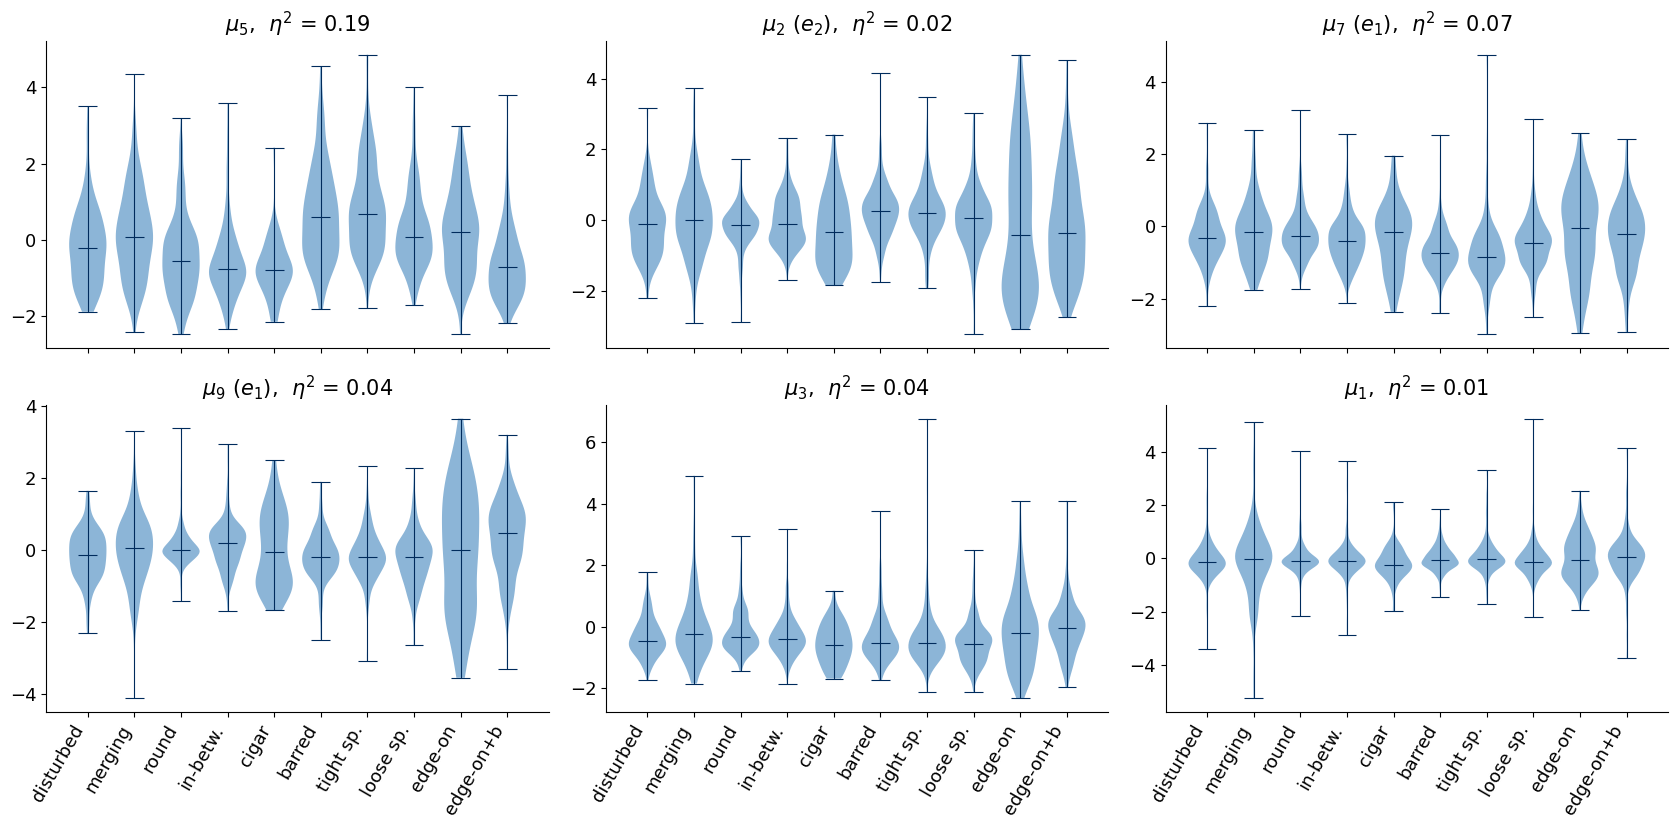

eta^2 (fraction of the variance of mu_k explained by the class): {5: 0.186, 2: 0.023, 7: 0.067, 9: 0.042, 3: 0.038, 1: 0.007}


In [18]:
show_k = active[4][:6]
fig, axs = plt.subplots(2, 3, figsize=(17, 8.5), sharex=True)
mu4_te = enc[4][0]
eta2 = {}
for a, k in zip(axs.ravel(), show_k):
    groups = [mu4_te[yte.numpy() == c, k] for c in range(10)]
    parts = a.violinplot(groups, positions=range(10), showmedians=True, widths=0.8)
    for pc in parts["bodies"]:
        pc.set_facecolor(UJBlue); pc.set_alpha(0.45)
    for key in ("cmedians", "cmins", "cmaxes", "cbars"):
        parts[key].set_color(UJNavy); parts[key].set_linewidth(0.8)
    allv = mu4_te[:, k]
    eta2[k] = sum(len(g) * (g.mean() - allv.mean()) ** 2 for g in groups) / (len(allv) * allv.var())
    lab = names[4].get(k)
    a.set_title(f"$\\mu_{{{k}}}$" + (f" ({QLABEL[lab]})" if lab else "") + f",  $\\eta^2$ = {eta2[k]:.2f}")
for a in axs[-1]:
    a.set_xticks(range(10)); a.set_xticklabels(SHORT, rotation=60, ha="right")
plt.tight_layout(); plt.show()
nums["eta2"] = {str(k): float(v) for k, v in eta2.items()}
print("eta^2 (fraction of the variance of mu_k explained by the class):",
      {k: round(float(v), 3) for k, v in eta2.items()})

<hr/>
## 7. Counterfactual explanations of a morphology classifier

The size–brightness coordinate $z_5$ separates the classes best ($\eta^2=0.19$): barred and tightly wound spirals are the largest and brightest galaxies in the images (median $R$ 12.8 and 12.9 pixels in the measurement table of Section 5), in-between and cigar-shaped smooth galaxies and edge-on disks with a bulge the smallest. The orientation coordinates have $\eta^2\le0.07$, as they should: a galaxy's orientation on the sky says nothing about its morphology. Their distributions nevertheless differ between classes in width rather than in mean. Edge-on disks spread over the whole range of $z_2$ and $z_9$, because they are strongly elongated in every direction on the sky, while round smooth galaxies stay near zero. The class information is in the length of the ellipticity vector, which $\eta^2$ of a single coordinate does not measure.

The β-VAE is unsupervised. The second network of this notebook is supervised: a convolutional neural network (CNN) that predicts the Galaxy Zoo class from the image. Four blocks of a $3\times3$ convolution, a ReLU and a $2\times2$ max pooling reduce the image to $64\times4\times4$ numbers, and two dense layers produce ten logits. The network is trained with the cross-entropy loss, Adam at learning rate $10^{-3}$ and minibatches of 128, for 10 epochs. Each minibatch is rotated by a multiple of $90^\circ$ and possibly mirrored, one of the eight symmetries of the square: the morphology of a galaxy does not depend on its orientation on the sky, and the augmentation tells the network so. The weights are stored in `checkpoints/` like those of the β-VAE.

In [19]:
class MorphologyCNN(nn.Module):
    """Four 3x3 convolution blocks with max pooling, then two dense layers; 10 class logits."""

    def __init__(self, ch=(16, 32, 64, 64), n_classes=10):
        super().__init__()
        c = [3, *ch]
        blocks = []
        for a, b in zip(c[:-1], c[1:]):
            blocks += [nn.Conv2d(a, b, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]
        self.net = nn.Sequential(*blocks, nn.Flatten(), nn.Dropout(0.3),
                                 nn.Linear(ch[-1] * 4 * 4, 128), nn.ReLU(), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.net(x)


def random_dihedral(x, gen):
    """Apply one of the 8 rotations/reflections of the square to the whole minibatch."""
    t = int(torch.randint(8, (1,), generator=gen))
    if t & 1:
        x = x.flip(3)
    if t & 2:
        x = x.flip(2)
    if t & 4:
        x = x.transpose(2, 3)
    return x


EPOCHS_CLF = 10


def train_classifier(seed=0, epochs=EPOCHS_CLF):
    path = f"{CKPT}/lab027_morphology_cnn_seed{seed}.pt"
    torch.manual_seed(seed)
    clf = MorphologyCNN().to(memory_format=torch.channels_last)
    if os.path.exists(path):
        ck = torch.load(path, weights_only=False)
        clf.load_state_dict(ck["state"])
        print(f"classifier loaded from {path} (trained {ck['train_time_s'] / 60:.1f} min)")
        return clf.eval(), ck["history"]
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(seed)
    hist, t0 = {"loss": [], "test_acc": []}, time.time()
    for ep in range(epochs):
        clf.train()
        order = torch.randperm(len(ytr), generator=gen)
        tot, nb = 0.0, 0
        for i in range(0, len(ytr) - BATCH + 1, BATCH):
            b = order[i:i + BATCH]
            loss = F.cross_entropy(clf(random_dihedral(Xtr[b], gen)), ytr[b])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        clf.eval()
        acc = (predict(clf, Xte).argmax(1) == yte.numpy()).mean()
        hist["loss"].append(tot / nb); hist["test_acc"].append(float(acc))
        print(f"  epoch {ep + 1:2d}: cross-entropy {tot / nb:.3f}  test accuracy {acc:.3f}  ({time.time() - t0:4.0f} s)")
    torch.save({"state": clf.state_dict(), "history": hist, "train_time_s": time.time() - t0}, path)
    return clf.eval(), hist


@torch.no_grad()
def predict(clf, X, chunk=1000):
    """Class probabilities, numpy array (n, 10)."""
    X = X.contiguous(memory_format=torch.channels_last)
    return torch.cat([F.softmax(clf(X[i:i + chunk]), 1) for i in range(0, X.shape[0], chunk)]).numpy()


clf, clf_hist = train_classifier()
P_real = predict(clf, Xte)
pred_real = P_real.argmax(1)
nums["clf_acc"] = float((pred_real == yte.numpy()).mean())
print(f"test accuracy on real images: {nums['clf_acc']:.3f} (largest class alone: {counts.max() / N_IMG:.3f})")

classifier loaded from checkpoints/lab027_morphology_cnn_seed0.pt (trained 6.0 min)


test accuracy on real images: 0.640 (largest class alone: 0.149)


The confusion matrix below summarises the classifier. Its entry $C_{ab}$ is the fraction of test galaxies of true class $a$ that the network assigns to class $b$, so the diagonal holds the recall of each class. After ten epochs the test accuracy is 0.640; always predicting the largest class would give 0.149. Round smooth galaxies and edge-on disks are recognised best (recall 0.87, 0.86 and 0.85), disturbed galaxies worst (0.07), and cigar-shaped smooth galaxies (0.24, the class with only 334 images) and barred spirals (0.39) are often confused with their neighbours in the Galaxy Zoo decision tree. These classes are defined by thresholds on vote fractions, so their boundaries are fuzzy even for humans.

The last lines of the output matter for what follows. On the reconstructions $\hat{\mathbf x}_\theta(\boldsymbol\mu)$ of the $\beta=4$ model the same classifier reaches only 0.315, and it gives the same answer as on the real image for 0.413 of the galaxies. The reconstructions lack exactly the arms, bars and companions that define several classes. The counterfactual analysis therefore compares every modified image with the unmodified reconstruction, never with the real image.

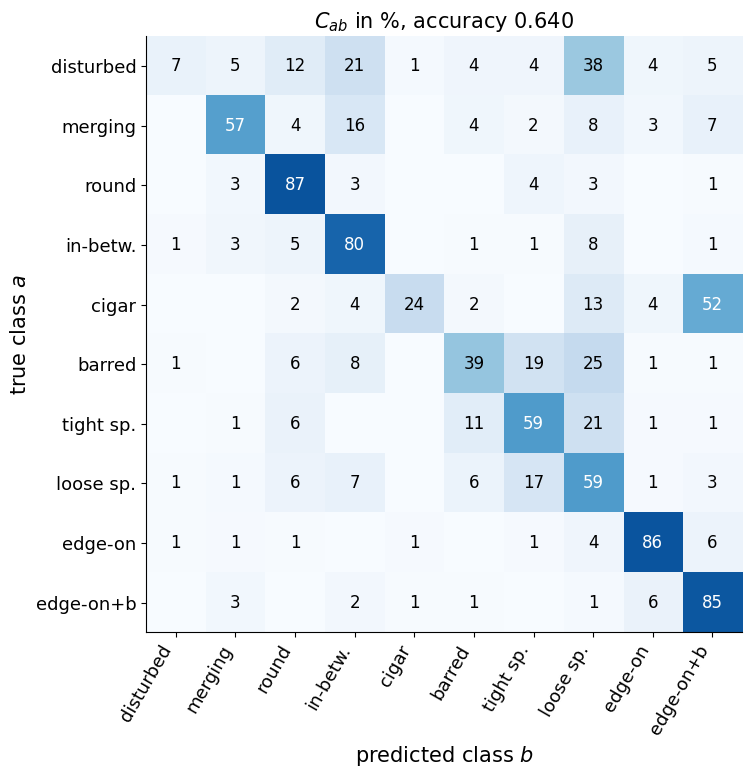

recall per class: {'disturbed': np.float64(0.07), 'merging': np.float64(0.57), 'round': np.float64(0.87), 'in-betw.': np.float64(0.8), 'cigar': np.float64(0.24), 'barred': np.float64(0.39), 'tight sp.': np.float64(0.59), 'loose sp.': np.float64(0.59), 'edge-on': np.float64(0.86), 'edge-on+b': np.float64(0.85)}


accuracy on beta=4 reconstructions x_hat(mu): 0.315; same prediction as on the real image: 0.413


In [20]:
def confusion(y_true, y_pred, n=10):
    C = np.zeros((n, n))
    np.add.at(C, (y_true, y_pred), 1)
    return C / C.sum(1, keepdims=True)


Cm = confusion(yte.numpy(), pred_real)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(Cm, cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        if round(100 * Cm[i, j]) >= 1:
            ax.text(j, i, f"{100 * Cm[i, j]:.0f}", ha="center", va="center", fontsize=12,
                    color="white" if Cm[i, j] > 0.5 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(SHORT, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(SHORT)
ax.set_xlabel("predicted class $b$"); ax.set_ylabel("true class $a$")
ax.set_title(f"$C_{{ab}}$ in %, accuracy {nums['clf_acc']:.3f}")
plt.tight_layout(); plt.show()
nums["clf_recall"] = np.diag(Cm).round(3).tolist()
print("recall per class:", dict(zip(SHORT, np.diag(Cm).round(2))))

x_rec4 = decode_all(models[4], enc[4][0])
pred_rec = predict(clf, x_rec4).argmax(1)
nums["clf_acc_recon"] = float((pred_rec == yte.numpy()).mean())
nums["clf_agree_recon_real"] = float((pred_rec == pred_real).mean())
print(f"accuracy on beta=4 reconstructions x_hat(mu): {nums['clf_acc_recon']:.3f}; "
      f"same prediction as on the real image: {nums['clf_agree_recon_real']:.3f}")

A counterfactual explanation answers a question of the form: what would the classifier have said if this galaxy were more inclined, with everything else unchanged? The β-VAE supplies the "everything else unchanged": we encode the galaxy, move one latent coordinate, decode, and show the new image to the classifier. For each of $N_{\rm cf}=600$ test galaxies and each active coordinate $k$ of the $\beta=4$ model we set

$$
\mathbf z=\boldsymbol\mu_\phi(\mathbf x)+\delta\,\mathbf e_k,\qquad\delta\in\{-3,-2,-1,0,1,2,3\},
$$

where $\mathbf e_k$ is the $k$-th unit vector, and classify $\hat{\mathbf x}_\theta(\mathbf z)$. The reference decision is the class predicted for the unmodified reconstruction ($\delta=0$), not for the real image, so that a change of decision is caused by the moved coordinate and not by the blur of the reconstruction. The flip rate $f_k(\delta)$ is the fraction of galaxies whose decision differs from the reference, and the sensitivity of the classifier to coordinate $k$ is $S_k=\tfrac12\big(f_k(-2)+f_k(2)\big)$.

In [21]:
N_CF = 600
DELTAS = np.array([-3, -2, -1, 0, 1, 2, 3], dtype=np.float32)
cf_idx = np.arange(N_CF)                       # the first N_CF test galaxies (the split is random)
mu_cf = enc[4][0][cf_idx]
cf_pred = {}                                   # k -> (len(DELTAS), N_CF) predicted classes
t0 = time.time()
for k in active[4]:
    Z = np.repeat(mu_cf[None], len(DELTAS), 0).copy()
    Z[:, :, k] += DELTAS[:, None]
    ims = decode_all(models[4], Z.reshape(-1, D_LATENT))
    cf_pred[k] = predict(clf, ims).argmax(1).reshape(len(DELTAS), N_CF)
base = cf_pred[active[4][0]][DELTAS == 0][0]     # prediction on the unmodified reconstruction
flip = {k: (cf_pred[k] != base[None]).mean(1) for k in active[4]}
sens = {k: float(flip[k][np.abs(DELTAS) == 2].mean()) for k in active[4]}
ranking = sorted(active[4], key=lambda k: -sens[k])
nums["flip_rate_delta2"] = {str(k): sens[k] for k in ranking}
nums["flip_rate_delta3"] = {str(k): float(flip[k][np.abs(DELTAS) == 3].mean()) for k in ranking}
print(f"{len(active[4])} coordinates x {len(DELTAS)} shifts x {N_CF} galaxies decoded and classified "
      f"in {time.time() - t0:.0f} s")
print("sensitivity ranking (flip rate at |delta| = 2):")
for k in ranking:
    print(f"  z_{k}: {sens[k]:.3f}" + (f"   [{names[4][k]}]" if k in names[4] else ""))

9 coordinates x 7 shifts x 600 galaxies decoded and classified in 27 s
sensitivity ranking (flip rate at |delta| = 2):
  z_2: 0.676   [e2]
  z_9: 0.639   [e1]
  z_5: 0.616
  z_7: 0.559   [e1]
  z_3: 0.434
  z_1: 0.247
  z_8: 0.144
  z_4: 0.106
  z_0: 0.102   [e2]


All nine active coordinates were moved for each of the 600 galaxies. The coordinates that change the image visibly move the decision most: at $|\delta|=2$ the flip rate is 0.68 for $z_2$ ($e_2$), 0.64 for $z_9$ ($e_1$), 0.62 for $z_5$ (size and brightness) and 0.56 for $z_7$ ($e_1$), and at most 0.25 for $z_1$, $z_8$, $z_4$ and $z_0$. The figure shows $f_k(\delta)$ for all coordinates. Two observations deserve attention. The flip rates are large because the classifier was trained to be insensitive to rotations, but an orientation coordinate does not rotate the galaxy: it elongates it along one axis, and elongation is what separates round, spiral and edge-on classes. And $z_0$ correlates with $e_2$ ($|\rho|=0.71$) yet flips only 0.10 of the decisions: the encoder writes information into it, but the decoder hardly uses it (its traversal shows no visible change), so a correlation alone does not make a coordinate influential.

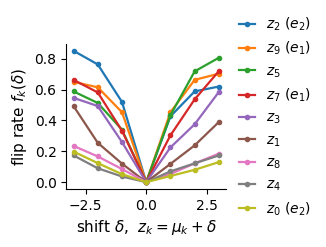

In [22]:
cols = plt.get_cmap("tab10")
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(3.4, 2.4))
    for i, k in enumerate(ranking):
        lab = f"$z_{{{k}}}$" + (f" ({QSYM[names[4][k]]})" if k in names[4] else "")
        ax.plot(DELTAS, flip[k], "o-", ms=3, color=cols(i), label=lab)
    ax.set_xlabel("shift $\\delta$,  $z_k = \\mu_k + \\delta$")
    ax.set_ylabel("flip rate $f_k(\\delta)$")
    ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), handlelength=1.2)
    plt.tight_layout(); save(fig, "gen_gal_flips.png"); plt.show()

Inclination is the factor one expects to turn a face-on spiral into an edge-on disk. Since no single coordinate carries $q$, the cell takes the coordinate most correlated with $q$, $z_7$ (an $e_1$ coordinate), orients it so that positive $\delta$ means smaller $q$, and follows the galaxies whose reconstruction the classifier calls a face-on spiral (classes 5–7).

In [23]:
k_q = active[4][int(np.argmax(np.abs(rho[4][:, QUANT.index("q")])))]   # coordinate most correlated with q
sign_q = -1.0 if rho[4][active[4].index(k_q), QUANT.index("q")] > 0 else 1.0   # direction in which q decreases
spiral = np.isin(base, [5, 6, 7])
d3 = DELTAS == 3 * sign_q
to_edge = np.isin(cf_pred[k_q][d3][0], [8, 9])
nums["incl_coord"] = int(k_q)
nums["n_spiral_base"] = int(spiral.sum())
nums["spiral_to_edgeon_delta3"] = float(to_edge[spiral].mean())
d3o = DELTAS == -3 * sign_q
nums["spiral_to_edgeon_opposite"] = float(np.isin(cf_pred[k_q][d3o][0], [8, 9])[spiral].mean())

# measured axis ratio of the decoded images along the shift, for the face-on spirals
ims_line = decode_all(models[4], np.concatenate([mu_cf[spiral] + np.eye(D_LATENT, dtype=np.float32)[k_q] * sign_q * d
                                                 for d in DELTAS]))
q_line = np.array([m["q"] if m is not None else np.nan for m in
                   (measure_galaxy(im) for im in ims_line.permute(0, 2, 3, 1).numpy())]).reshape(7, -1)
nums["q_decoded_median"] = np.nanmedian(q_line, 1).round(3).tolist()
print(f"coordinate most correlated with q: z_{k_q}; {spiral.sum()} galaxies with a face-on spiral prediction (classes 5-7) "
      f"on the reconstruction")
print(f"  moved towards smaller q by 3: predicted edge-on (8 or 9) in {nums['spiral_to_edgeon_delta3']:.3f}")
print(f"  moved the opposite way by 3:  predicted edge-on in {nums['spiral_to_edgeon_opposite']:.3f}")
print("  median measured q of the decoded images, shift -3 ... +3 towards smaller q:", nums["q_decoded_median"])

coordinate most correlated with q: z_7; 249 galaxies with a face-on spiral prediction (classes 5-7) on the reconstruction
  moved towards smaller q by 3: predicted edge-on (8 or 9) in 0.124
  moved the opposite way by 3:  predicted edge-on in 0.064
  median measured q of the decoded images, shift -3 ... +3 towards smaller q: [0.604, 0.641, 0.66, 0.651, 0.549, 0.438, 0.374]


Of the 249 galaxies with a face-on spiral decision, 12.4% are classified as edge-on (class 8 or 9) after a shift of $\delta=3$ towards smaller $q$, and 6.4% after a shift by 3 the other way. The measured axis ratio of the decoded images confirms that the shift does what its name says: its median falls from 0.65 at $\delta=0$ to 0.37 at $\delta=3$. It also falls slightly, to 0.60, at $\delta=-3$, because the opposite direction elongates the galaxy along the other axis; this is why the opposite shift also produces some edge-on decisions. The figure shows two galaxies that Galaxy Zoo labels as face-on spirals and whose reconstruction the classifier also calls a spiral: the decision of the first turns edge-on along the shift, that of the second does not. Above each image are the predicted class and the probability the classifier assigns to it.

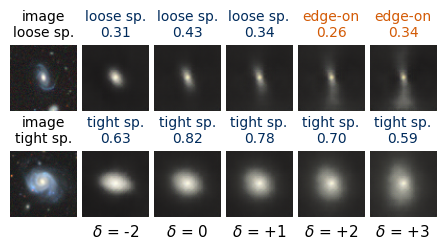

In [24]:
# two galaxies labelled as face-on spirals by Galaxy Zoo and predicted as such on the reconstruction:
# one whose decision turns edge-on at delta = 3 and one whose decision does not
true_sp = np.isin(yte.numpy()[cf_idx], [5, 6, 7])
flips_sp = np.flatnonzero(spiral & true_sp & to_edge)
stays_sp = np.flatnonzero(spiral & true_sp & ~to_edge)
ex = [a[0] for a in (flips_sp, stays_sp) if len(a)]
SHOW_D = np.array([-2, 0, 1, 2, 3], dtype=np.float32)      # delta, positive = towards smaller q
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(len(ex), len(SHOW_D) + 1, figsize=(SLIDE_W, 2.3), squeeze=False)
    for r, i in enumerate(ex):
        axs[r, 0].imshow(Xte_np[cf_idx[i]])
        axs[r, 0].set_title(f"image\n{SHORT[int(yte[cf_idx[i]])]}", fontsize=10)
        Z = np.repeat(mu_cf[i][None], len(SHOW_D), 0).copy()
        Z[:, k_q] += sign_q * SHOW_D
        ims = decode_all(models[4], Z)
        P = predict(clf, ims)
        for c in range(len(SHOW_D)):
            a = axs[r, c + 1]
            a.imshow(ims[c].permute(1, 2, 0).numpy())
            p = P[c].argmax()
            a.set_title(f"{SHORT[p]}\n{P[c, p]:.2f}", fontsize=10, color=DSOrange if p in (8, 9) else UJNavy)
            if r == len(ex) - 1:
                a.set_xlabel("$\\delta$ = 0" if SHOW_D[c] == 0 else f"$\\delta$ = {SHOW_D[c]:+.0f}")
    for a in axs.ravel():
        image_axes(a)
    plt.subplots_adjust(wspace=0.08, hspace=0.5)
    save(fig, "gen_gal_counterfactual.png"); plt.show()

The most sensitive coordinate, $z_2$, is an orientation ($e_2$) coordinate, and the most frequent flips at $|\delta|=3$ show what it does to the classifier: round smooth galaxies become loose spirals (213 cases out of 1,200 shifted images) or edge-on disks (168), loose spirals become edge-on disks (136). Stretching a blob makes it look like a disk, and stretching it further makes it look like a disk seen from the side. The classifier responds to the elongation of the light distribution in a physically sensible way; that it calls a stretched, featureless blob a "loose spiral" shows how far these images are from the training data.

In [25]:
k_top = ranking[0]
T = np.zeros((10, 10))
for d in (-3, 3):
    np.add.at(T, (base, cf_pred[k_top][DELTAS == d][0]), 1)
np.fill_diagonal(T, 0)
pairs = sorted(((T[a, b], a, b) for a in range(10) for b in range(10) if T[a, b] > 0), reverse=True)[:6]
nums["top_coord"] = int(k_top)
nums["top_transitions"] = [[SHORT[a], SHORT[b], int(n)] for n, a, b in pairs]
print(f"most sensitive coordinate z_{k_top} ({names[4].get(k_top, 'not named')}); most frequent flips at |delta| = 3:")
for n, a, b in pairs:
    print(f"  {SHORT[a]:>14s} -> {SHORT[b]:<14s} {int(n)}")

most sensitive coordinate z_2 (e2); most frequent flips at |delta| = 3:
           round -> loose sp.      213
           round -> edge-on        168
       loose sp. -> edge-on        136
        in-betw. -> loose sp.      90
        in-betw. -> edge-on        64
       tight sp. -> edge-on        59


<hr/>
## 8. Limits of unsupervised disentanglement

The analysis above rests on assumptions that the data cannot check. Locatello *et al.* proved that for a factorised prior there are infinitely many invertible maps of the latent space that leave the distribution of $\mathbf z$, and therefore the distribution of generated images, unchanged, while mixing every factor into every coordinate [Locatello *et al.*, ICML 2019, [arXiv:1811.12359](https://arxiv.org/abs/1811.12359)]. A loss that sees only images cannot prefer the disentangled member of this family; unsupervised disentangling is not identifiable without inductive biases on the model and the data. In their large study of trained models, the random seed and the hyperparameters influenced the result more than the choice of the objective, and good models could not be selected without access to the true factors. Here the inductive biases are the diagonal posterior, the convolutional architecture and $\beta$; the "true factors" are replaced by quantities we chose to measure.

The cell below makes the dependence on the seed concrete: it trains the $\beta=4$ model once more, with seed 1 instead of 0 and nothing else changed, and compares the number of active coordinates, the named coordinates, the largest $|\rho|$ for each quantity and the correlation gap with those of the two models of Section 3.

In [26]:
model_s1, hist_s1 = train_vae(4, seed=1)
mu_s1, lv_s1 = encode_all(model_s1, Xte)
kl_s1 = (0.5 * (mu_s1 ** 2 + np.exp(lv_s1) - lv_s1 - 1)).mean(0)
active_s1 = [int(k) for k in np.argsort(-kl_s1) if kl_s1[k] > KL_ACTIVE]
rho_s1 = spearman_matrix(mu_s1[ok], Q[ok], active_s1)
names_s1 = name_coordinates(rho_s1, active_s1)
gap_s1 = correlation_gap(rho_s1)
nums["seed1"] = {"n_active": len(active_s1), "named": {str(k): v for k, v in names_s1.items()},
                 "max_abs_rho": dict(zip(QUANT, np.abs(rho_s1).max(0, initial=0).round(3).tolist())),
                 "corr_gap_mean": float(gap_s1.mean())}
print(f"{'':22s}" + " ".join(f"{k:>6s}" for k in QUANT))
for lab, r_ in [("beta=1, seed 0", rho[1]), ("beta=4, seed 0", rho[4]), ("beta=4, seed 1", rho_s1)]:
    print(f"{lab + ' max |rho|':22s}" + " ".join(f"{v:6.2f}" for v in np.abs(r_).max(0, initial=0)))
for lab, g in [("beta=1, seed 0", gap[1]), ("beta=4, seed 0", gap[4]), ("beta=4, seed 1", gap_s1)]:
    print(f"{lab + ' gap':22s}" + " ".join(f"{v:6.2f}" for v in g) + f"   mean {g.mean():.3f}")
print("active coordinates:", {"beta=1": len(active[1]), "beta=4 seed 0": len(active[4]), "beta=4 seed 1": len(active_s1)})
print("named coordinates, beta=4 seed 0:", names[4], "| seed 1:", names_s1)

beta=4, seed=1: weights loaded from checkpoints/lab027_bvae_beta4_seed1.pt (trained 1.0 min)


                           R      q     e1     e2      F      c      C
beta=1, seed 0 max |rho|  0.91   0.22   0.82   0.70   0.94   0.27   0.24
beta=4, seed 0 max |rho|  0.93   0.13   0.80   0.78   0.97   0.22   0.15
beta=4, seed 1 max |rho|  0.93   0.17   0.79   0.59   0.96   0.26   0.22
beta=1, seed 0 gap      0.22   0.06   0.25   0.04   0.21   0.05   0.02   mean 0.122
beta=4, seed 0 gap      0.57   0.01   0.20   0.07   0.58   0.09   0.00   mean 0.218
beta=4, seed 1 gap      0.26   0.05   0.25   0.01   0.23   0.07   0.10   mean 0.141
active coordinates: {'beta=1': 10, 'beta=4 seed 0': 9, 'beta=4 seed 1': 10}
named coordinates, beta=4 seed 0: {2: 'e2', 7: 'e1', 9: 'e1', 0: 'e2'} | seed 1: {4: 'e2', 6: 'e1'}


The second seed reaches the same rate (11.5 nats per image in the last training epoch) and finds the same kind of factors: the largest $|\rho|$ with size and brightness is 0.93 and 0.96, with $e_1$ 0.79. The organisation differs. The seed-1 model keeps all 10 coordinates active instead of 9, spreads size and brightness over several coordinates (correlation gap 0.26 and 0.23 instead of 0.57 and 0.58) and names only two coordinates instead of four; its mean gap, 0.141, is closer to the $\beta=1$ model (0.122) than to the seed-0 $\beta=4$ model (0.218). With two seeds we cannot tell whether $\beta=4$ disentangles better than $\beta=1$ on these images, only that the seed matters as much as $\beta$, as Locatello *et al.* found on larger studies.

Three further limits concern the counterfactuals. A decoded image at $\delta=\pm3$ is not a real galaxy; it is a blurred, grey blob that may lie outside the distribution of images the classifier was trained on, and the classifier's answer to it may say more about the blur than about morphology (the classifier already disagrees with itself on 59% of the plain reconstructions). The β-VAE at 64 pixels and ten nats per image does not represent arms, bars or companions, so it cannot produce counterfactuals that add or remove them, and the factors it can move are the coarse ones. And the names we gave rest on quantities we chose to measure, with a threshold, a mask and a margin rule that are choices too.

<hr/>
## Summary

A β-VAE trained without labels on 15,000 galaxy images of the Galaxy10 DECaLS set stores about 25 nats per image at $\beta=1$ and 11 nats at $\beta=4$, with nearly the same reconstruction error. What it stores is the coarse light distribution: size and brightness, which travel together in one coordinate at $\beta=4$, and the shape as the two ellipticity components $(e_1,e_2)$, spread over two coordinates each. Colour, arms and bars are not stored. Rank correlations with quantities measured from the pixels, size, axis ratio, ellipticity, brightness, colour and concentration, turned the traversals into named coordinates, and showed that the axis ratio is not a coordinate but the length of the ellipticity vector. A convolutional classifier reaches an accuracy of 0.640 on ten classes; moving one latent coordinate and decoding changes its decision most often for the orientation and size coordinates, and turns 12% of the face-on spirals into edge-on disks when the galaxy is elongated. The analysis is not identifiable: a second seed found the same factors organised differently, the counterfactual images are far from real galaxies, and every name rests on measured quantities we chose.

Exercises:

1. Replace the Gaussian decoder by the binary cross-entropy of Lab 024 and count the active coordinates of a $\beta=1$ model. Explain the result through the curvature of the binary cross-entropy at the sky value of the pixels.
2. Train models with $\beta\in\{2,8\}$ and plot the mean correlation gap against $\beta$, together with the test mean squared error. Where does the trade-off lie for these images?
3. Replace the posterior means $\mu_k$ by the measured quantities themselves: fit a linear map from the seven quantities to $\boldsymbol\mu$ and decode galaxies with a chosen axis ratio. Which properties of the decoded image follow?
4. Train the classifier on the reconstructions $\hat{\mathbf x}_\theta(\boldsymbol\mu)$ instead of the real images and repeat the counterfactual analysis. Which flips survive?
5. Move the two coordinates with the largest sensitivity $S_k$ at once and describe the region of the latent plane in which the classifier answers "edge-on with bulge".

References

- H. W. Leung, J. Bovy, *Galaxy10 DECaLS*, Zenodo (2024), CC BY 4.0, [doi:10.5281/zenodo.10845026](https://doi.org/10.5281/zenodo.10845026); documentation [astronn.readthedocs.io/en/latest/galaxy10.html](https://astronn.readthedocs.io/en/latest/galaxy10.html); compilation code [github.com/henrysky/Galaxy10](https://github.com/henrysky/Galaxy10).
- M. Walmsley *et al.*, *Galaxy Zoo DECaLS: Detailed visual morphology measurements from volunteers and deep learning for 314 000 galaxies*, MNRAS **509**, 3966 (2022), [doi:10.1093/mnras/stab2093](https://doi.org/10.1093/mnras/stab2093).
- A. Dey *et al.*, *Overview of the DESI Legacy Imaging Surveys*, AJ **157**, 168 (2019), [doi:10.3847/1538-3881/ab089d](https://doi.org/10.3847/1538-3881/ab089d).
- D. P. Kingma, M. Welling, *Auto-Encoding Variational Bayes*, [arXiv:1312.6114](https://arxiv.org/abs/1312.6114).
- I. Higgins *et al.*, *β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework*, ICLR 2017, [openreview.net/forum?id=Sy2fzU9gl](https://openreview.net/forum?id=Sy2fzU9gl).
- C. P. Burgess *et al.*, *Understanding disentangling in β-VAE*, [arXiv:1804.03599](https://arxiv.org/abs/1804.03599).
- R. T. Q. Chen, X. Li, R. Grosse, D. Duvenaud, *Isolating Sources of Disentanglement in Variational Autoencoders*, [arXiv:1802.04942](https://arxiv.org/abs/1802.04942).
- M. Rolinek, D. Zietlow, G. Martius, *Variational Autoencoders Pursue PCA Directions (by Accident)*, [arXiv:1812.06775](https://arxiv.org/abs/1812.06775).
- F. Locatello *et al.*, *Challenging Common Assumptions in the Unsupervised Learning of Disentangled Representations*, ICML 2019, [arXiv:1811.12359](https://arxiv.org/abs/1811.12359).